In [1]:

%pip install shap


   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 7.0 MB/s  0:00:00

   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ------------- -------------------------- 1/3 [slicer]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   ---------------------------------------- 3/3 [shap]

Note: you may need to restart the kernel to use updated packages.


In [1]:
import shap
print("SHAP version:", shap.__version__)
print("SHAP ready!")

D:\Fraud-Detection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP version: 0.54.1
SHAP ready!


In [2]:
%pip install ipywidgets

   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.2 MB ? eta -:--:--
   --------- ------------------------------ 0.5/2.2 MB 1.4 MB/s eta 0:00:02
   -------------- ------------------------- 0.8/2.2 MB 1.5 MB/s eta 0:00:01
   ------------------ --------------------- 1.0/2.2 MB 1.5 MB/s eta 0:00:01
   ----------------------- ---------------- 1.3/2.2 MB 1.5 MB/s eta 0:00:01
   -------------------------------- ------- 1.8/2.2 MB 1.6 MB/s eta 0:00:01
   ---------------------------------------- 2.2/2.2 MB 1.6 MB/s  0:00:01

   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   ---------------------------------------- 3/3 [ipywidgets]

Note: you may need to restart the kernel 

In [1]:

import joblib
import lightgbm as lgb
import pandas as pd
import numpy as np

bce_model = joblib.load(MODELS_DIR / "bce_model.pkl")
focal_model = joblib.load(MODELS_DIR / "focal_alpha75_model.pkl")

X_val = joblib.load(RESULTS_DIR / "X_val.pkl")
y_val = joblib.load(RESULTS_DIR / "y_val.pkl")

X_test = joblib.load(RESULTS_DIR / "X_test.pkl")
y_test = joblib.load(RESULTS_DIR / "y_test.pkl")

print("Models and datasets loaded successfully!")

print("BCE features:", bce_model.num_feature())
print("Focal features:", focal_model.num_feature())

print("Validation:", X_val.shape)
print("Test:", X_test.shape)


NameError: name 'MODELS_DIR' is not defined

In [2]:

bce_features = bce_model.feature_name()
focal_features = focal_model.feature_name()

print("BCE and Focal features match:",
      bce_features == focal_features)

print("BCE and validation features match:",
      bce_features == list(X_val.columns))

print("Test and validation columns match:",
      list(X_test.columns) == list(X_val.columns))

assert bce_features == list(X_val.columns)
assert focal_features == list(X_val.columns)
assert list(X_test.columns) == list(X_val.columns)

print("\nALL FEATURE CHECKS PASSED!")


NameError: name 'bce_model' is not defined

In [3]:

bce_val_predictions = bce_model.predict(
    X_val,
    num_iteration=bce_model.best_iteration
)

focal_val_predictions = focal_model.predict(
    X_val,
    num_iteration=focal_model.best_iteration
)

print("BCE predictions:", bce_val_predictions.shape)
print("Focal predictions:", focal_val_predictions.shape)

print("BCE range:",
      bce_val_predictions.min(),
      bce_val_predictions.max())

print("Focal range:",
      focal_val_predictions.min(),
      focal_val_predictions.max())

print("Validation fraud rate:", y_val.mean())


NameError: name 'bce_model' is not defined

In [4]:

# ============================================================
# 1. PROJECT INITIALIZATION
# ============================================================

from pathlib import Path
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path(r"D:\Fraud-Detection")

DATA_DIR = PROJECT_DIR / "data"
RAW_DIR = DATA_DIR / "raw"

MODELS_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
NOTEBOOKS_DIR = PROJECT_DIR / "notebooks"

MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42

print("Project:", PROJECT_DIR)
print("Models directory:", MODELS_DIR)
print("Results directory:", RESULTS_DIR)

assert PROJECT_DIR.exists()

print("\nPROJECT INITIALIZATION SUCCESSFUL!")


Project: D:\Fraud-Detection
Models directory: D:\Fraud-Detection\models
Results directory: D:\Fraud-Detection\results

PROJECT INITIALIZATION SUCCESSFUL!


In [5]:

# ============================================================
# 2. LOAD EXISTING MODELS AND DATASETS
# ============================================================

import lightgbm as lgb

bce_model = joblib.load(MODELS_DIR / "bce_model.pkl")
focal_model = joblib.load(MODELS_DIR / "focal_alpha75_model.pkl")

X_val = joblib.load(RESULTS_DIR / "X_val.pkl")
y_val = joblib.load(RESULTS_DIR / "y_val.pkl")

X_test = joblib.load(RESULTS_DIR / "X_test.pkl")
y_test = joblib.load(RESULTS_DIR / "y_test.pkl")

print("Models and datasets loaded successfully!")

print("BCE features:", bce_model.num_feature())
print("Focal features:", focal_model.num_feature())

print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Models and datasets loaded successfully!
BCE features: 441
Focal features: 441
Validation: (88581, 441)
Test: (88581, 441)


In [6]:

bce_features = bce_model.feature_name()
focal_features = focal_model.feature_name()

print("BCE and Focal features match:",
      bce_features == focal_features)

print("BCE and validation features match:",
      bce_features == list(X_val.columns))

print("Test and validation columns match:",
      list(X_test.columns) == list(X_val.columns))

assert bce_features == list(X_val.columns)
assert focal_features == list(X_val.columns)
assert list(X_test.columns) == list(X_val.columns)

print("\nALL FEATURE CHECKS PASSED!")


BCE and Focal features match: True
BCE and validation features match: True
Test and validation columns match: True

ALL FEATURE CHECKS PASSED!


In [7]:

bce_val_predictions = bce_model.predict(
    X_val,
    num_iteration=bce_model.best_iteration
)

focal_val_predictions = focal_model.predict(
    X_val,
    num_iteration=focal_model.best_iteration
)

print("BCE predictions:", bce_val_predictions.shape)
print("Focal predictions:", focal_val_predictions.shape)

print("BCE prediction range:",
      bce_val_predictions.min(),
      bce_val_predictions.max())

print("Focal prediction range:",
      focal_val_predictions.min(),
      focal_val_predictions.max())

print("Validation fraud rate:", y_val.mean())


BCE predictions: (88581,)
Focal predictions: (88581,)
BCE prediction range: 0.0006055822997660303 0.986008312584323
Focal prediction range: -2.525791575310411 2.1333337798472987
Validation fraud rate: 0.03434145019812375


In [8]:

# ============================================================
# SHAP: PREPARE VALIDATION SAMPLE
# ============================================================

import shap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SHAP_SAMPLE_SIZE = 2000

X_shap = X_val.sample(
    n=SHAP_SAMPLE_SIZE,
    random_state=RANDOM_STATE
).copy()

print("SHAP sample shape:", X_shap.shape)

print("\nFraud distribution in sample:")
print(y_val.loc[X_shap.index].value_counts())

print("\nSHAP version:", shap.__version__)


SHAP sample shape: (2000, 441)

Fraud distribution in sample:
isFraud
0    1921
1      79
Name: count, dtype: int64

SHAP version: 0.54.1


BCE SHAP calculation completed!
SHAP values shape: (2000, 441)


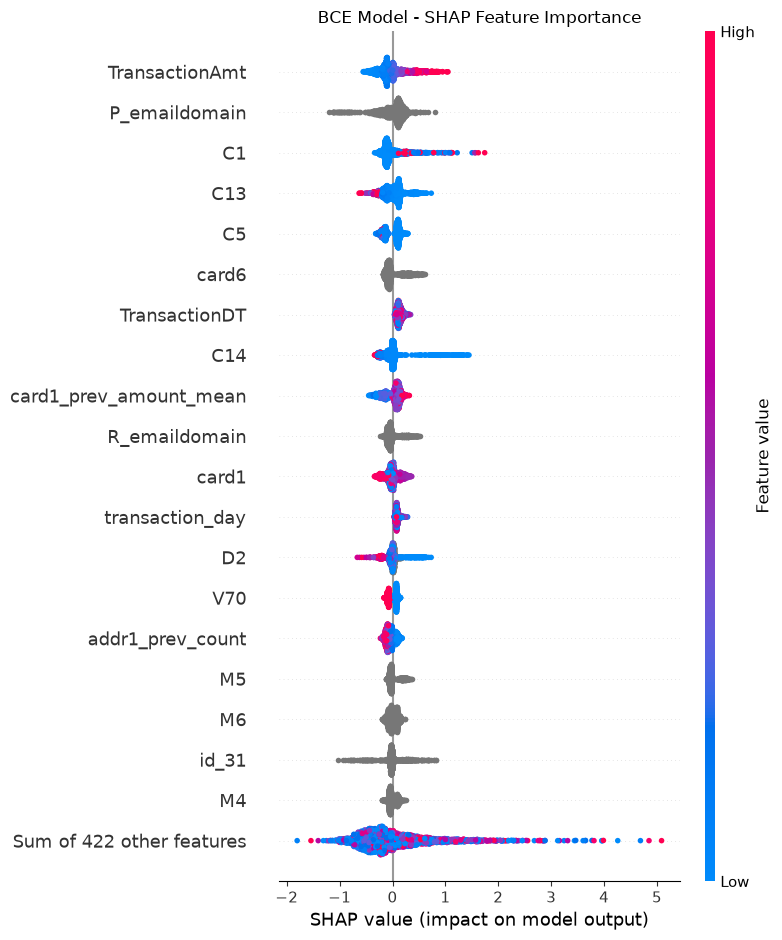

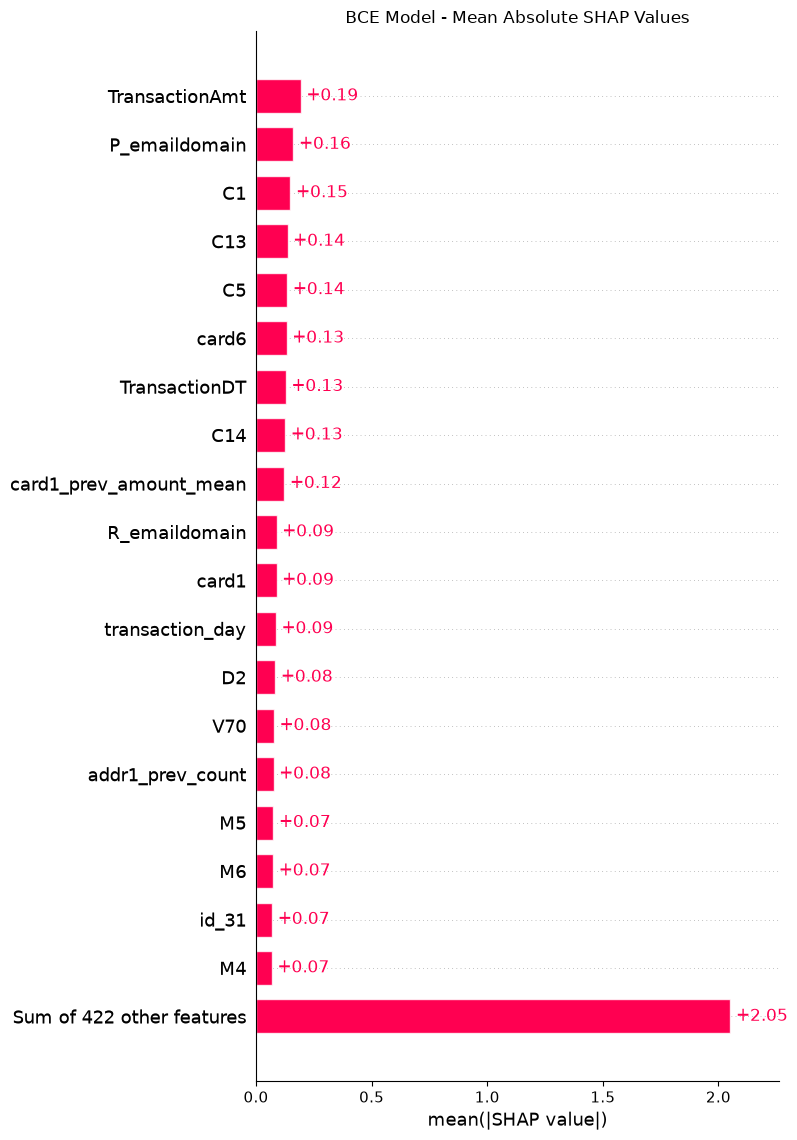

In [9]:

# ============================================================
# SHAP TREE EXPLAINER: BCE MODEL
# ============================================================

bce_explainer = shap.TreeExplainer(bce_model)

bce_shap_values = bce_explainer(
    X_shap,
    check_additivity=False
)

print("BCE SHAP calculation completed!")
print("SHAP values shape:", bce_shap_values.values.shape)

# Beeswarm summary plot
plt.figure()
shap.plots.beeswarm(
    bce_shap_values,
    max_display=20,
    show=False
)

plt.title("BCE Model - SHAP Feature Importance")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "shap_bce_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Global feature importance
plt.figure()
shap.plots.bar(
    bce_shap_values,
    max_display=20,
    show=False
)

plt.title("BCE Model - Mean Absolute SHAP Values")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "shap_bce_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Focal SHAP calculation completed!
SHAP values shape: (2000, 441)


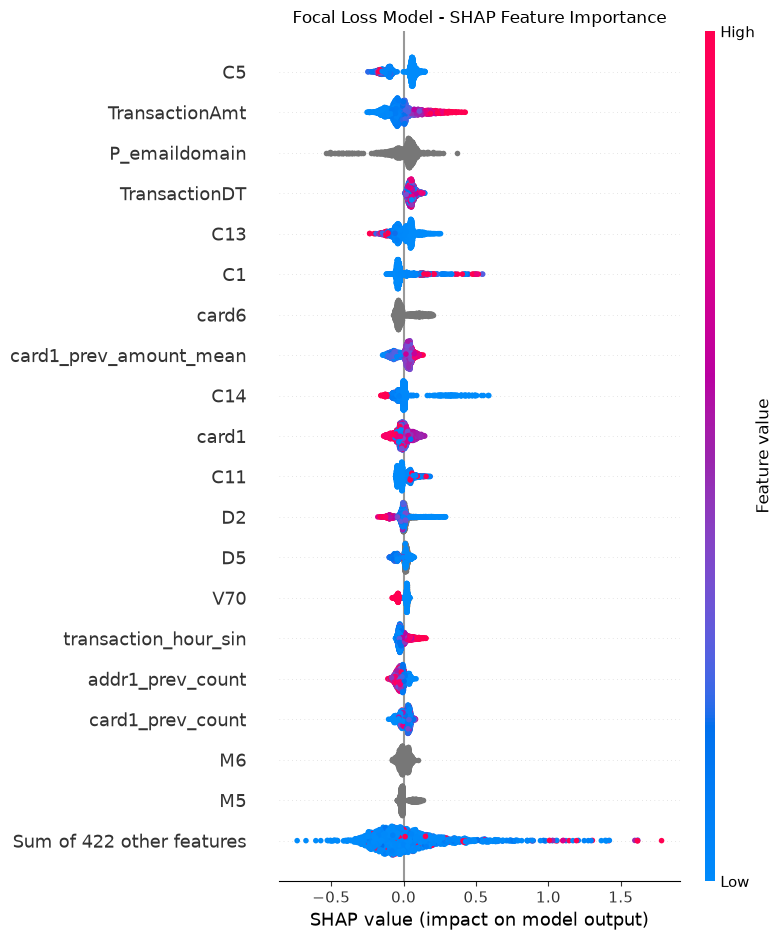

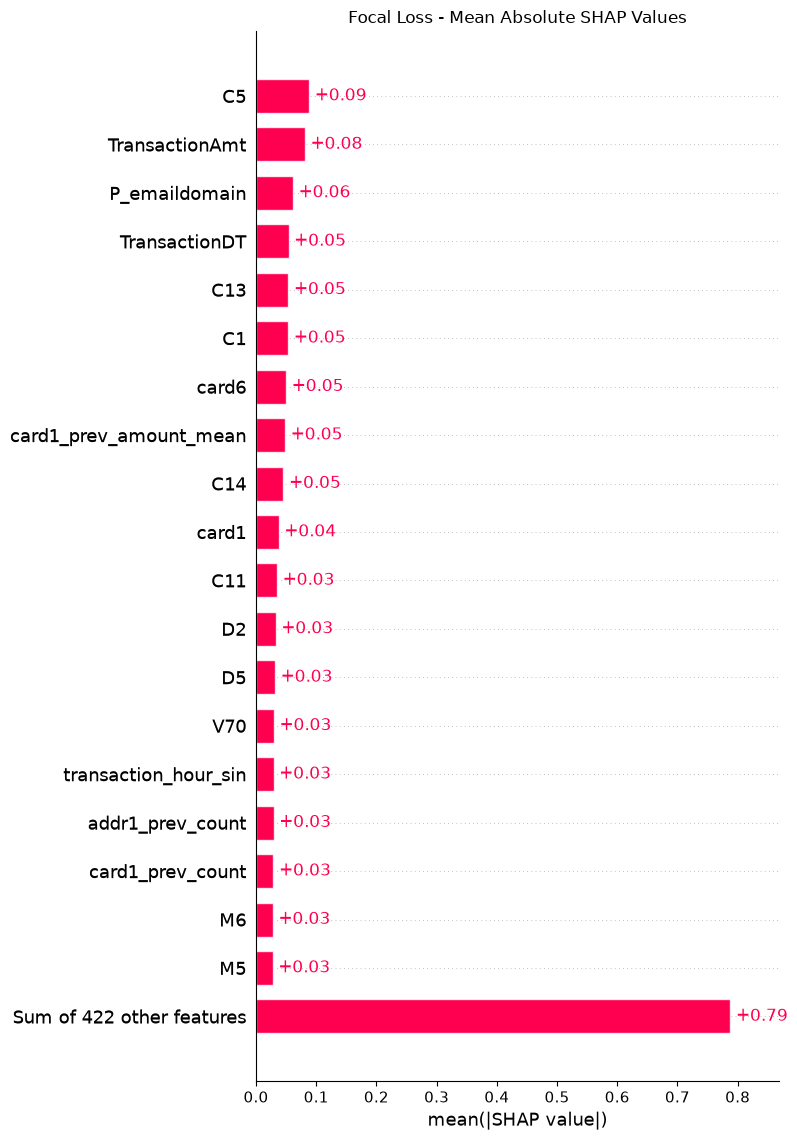

In [10]:

# ============================================================
# SHAP TREE EXPLAINER: FOCAL LOSS ALPHA 0.75
# ============================================================

focal_explainer = shap.TreeExplainer(focal_model)

focal_shap_values = focal_explainer(
    X_shap,
    check_additivity=False
)

print("Focal SHAP calculation completed!")
print("SHAP values shape:", focal_shap_values.values.shape)

# Beeswarm summary plot
plt.figure()

shap.plots.beeswarm(
    focal_shap_values,
    max_display=20,
    show=False
)

plt.title("Focal Loss Model - SHAP Feature Importance")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "shap_focal_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Global feature importance
plt.figure()

shap.plots.bar(
    focal_shap_values,
    max_display=20,
    show=False
)

plt.title("Focal Loss - Mean Absolute SHAP Values")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "shap_focal_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [11]:

# ============================================================
# COMPARE SHAP FEATURE IMPORTANCE
# ============================================================

bce_importance = np.abs(
    bce_shap_values.values
).mean(axis=0)

focal_importance = np.abs(
    focal_shap_values.values
).mean(axis=0)

shap_comparison = pd.DataFrame({
    "Feature": X_shap.columns,
    "BCE_SHAP_Importance": bce_importance,
    "Focal_SHAP_Importance": focal_importance
})

shap_comparison = shap_comparison.sort_values(
    "BCE_SHAP_Importance",
    ascending=False
)

shap_comparison.to_csv(
    RESULTS_DIR / "shap_feature_comparison.csv",
    index=False
)

print("TOP 20 SHAP FEATURES")
display(shap_comparison.head(20))


TOP 20 SHAP FEATURES


,Feature,BCE_SHAP_Importance,Focal_SHAP_Importance
1,TransactionAmt,0.193621,0.081264
13,P_emaildomain,0.161711,0.061445
15,C1,0.148908,0.053484
27,C13,0.136304,0.053728
19,C5,0.135040,0.088274
8,card6,0.132418,0.050033
0,TransactionDT,0.128647,0.053984
28,C14,0.126313,0.045575
439,card1_prev_amount_mean,0.122406,0.048309
14,R_emaildomain,0.088982,0.014762


In [12]:

# ============================================================
# VERIFY SHAP OUTPUT FILES
# ============================================================

shap_files = [
    "shap_bce_summary.png",
    "shap_bce_importance.png",
    "shap_focal_summary.png",
    "shap_focal_importance.png",
    "shap_feature_comparison.csv"
]

for filename in shap_files:
    path = RESULTS_DIR / filename

    print(
        filename,
        "->",
        "SAVED" if path.exists() else "MISSING"
    )

print("\nTOP 10 SHAP FEATURES")
display(shap_comparison.head(10))


shap_bce_summary.png -> SAVED
shap_bce_importance.png -> SAVED
shap_focal_summary.png -> SAVED
shap_focal_importance.png -> SAVED
shap_feature_comparison.csv -> SAVED

TOP 10 SHAP FEATURES


,Feature,BCE_SHAP_Importance,Focal_SHAP_Importance
1,TransactionAmt,0.193621,0.081264
13,P_emaildomain,0.161711,0.061445
15,C1,0.148908,0.053484
27,C13,0.136304,0.053728
19,C5,0.135040,0.088274
8,card6,0.132418,0.050033
0,TransactionDT,0.128647,0.053984
28,C14,0.126313,0.045575
439,card1_prev_amount_mean,0.122406,0.048309
14,R_emaildomain,0.088982,0.014762


In [13]:

# ============================================================
# INSPECT EXISTING THRESHOLD SELECTION
# ============================================================

threshold_path = RESULTS_DIR / "final_threshold_selection.csv"

threshold_df = pd.read_csv(threshold_path)

print("EXISTING THRESHOLD SELECTION")
print("=" * 60)

display(threshold_df)

print("\nExisting threshold comparison:")
display(
    pd.read_csv(
        RESULTS_DIR / "focal_threshold_comparison.csv"
    )
)


EXISTING THRESHOLD SELECTION


,Model,Threshold,Precision,Recall,F1 Score
0,BCE,0.16,0.417920,0.460317,0.438095
1,Focal Alpha 0.75,0.33,0.597274,0.332643,0.427305



Existing threshold comparison:


,Model,Best Threshold,Precision,Recall,F1 Score
0,BCE,0.29,0.679174,0.421420,0.520115
1,Focal Alpha 0.25,0.35,0.760181,0.391153,0.516526
2,Focal Alpha 0.75,0.47,0.620800,0.451688,0.522911


In [15]:

# Load existing Platt calibrators

bce_platt = joblib.load(
    RESULTS_DIR / "bce_platt_calibrator.pkl"
)

focal_platt = joblib.load(
    RESULTS_DIR / "focal_alpha_0.75_platt_calibrator.pkl"
)

print("BCE calibrator:", type(bce_platt).__name__)
print("Focal calibrator:", type(focal_platt).__name__)

print("Both calibrators loaded successfully!")


BCE calibrator: LogisticRegression
Focal calibrator: LogisticRegression
Both calibrators loaded successfully!


In [16]:

# Raw model scores on validation data

bce_raw = bce_model.predict(X_val)
focal_raw = focal_model.predict(X_val)

# Platt calibrated probabilities

bce_calibrated = bce_platt.predict_proba(
    bce_raw.reshape(-1, 1)
)[:, 1]

focal_calibrated = focal_platt.predict_proba(
    focal_raw.reshape(-1, 1)
)[:, 1]

# Create comparison table

score_audit = pd.DataFrame({
    "Model": [
        "BCE Raw",
        "BCE Platt",
        "Focal Raw",
        "Focal Platt"
    ],
    "Minimum": [
        bce_raw.min(),
        bce_calibrated.min(),
        focal_raw.min(),
        focal_calibrated.min()
    ],
    "Maximum": [
        bce_raw.max(),
        bce_calibrated.max(),
        focal_raw.max(),
        focal_calibrated.max()
    ],
    "Mean": [
        bce_raw.mean(),
        bce_calibrated.mean(),
        focal_raw.mean(),
        focal_calibrated.mean()
    ]
})

display(score_audit)


,Model,Minimum,Maximum,Mean
0,BCE Raw,0.000606,0.986008,0.033401
1,BCE Platt,0.568618,0.795758,0.577082
2,Focal Raw,-2.525792,2.133334,-1.364739
3,Focal Platt,0.000360,0.995408,0.033862


In [17]:

# Load existing threshold selection

threshold_selection = pd.read_csv(
    RESULTS_DIR / "final_threshold_selection.csv"
)

print("FINAL THRESHOLD SELECTION")
display(threshold_selection)


FINAL THRESHOLD SELECTION


,Model,Threshold,Precision,Recall,F1 Score
0,BCE,0.16,0.417920,0.460317,0.438095
1,Focal Alpha 0.75,0.33,0.597274,0.332643,0.427305


In [18]:

focal_threshold_results = pd.read_csv(
    RESULTS_DIR / "focal_threshold_comparison.csv"
)

print("FOCAL THRESHOLD COMPARISON")
display(focal_threshold_results)


FOCAL THRESHOLD COMPARISON


,Model,Best Threshold,Precision,Recall,F1 Score
0,BCE,0.29,0.679174,0.421420,0.520115
1,Focal Alpha 0.25,0.35,0.760181,0.391153,0.516526
2,Focal Alpha 0.75,0.47,0.620800,0.451688,0.522911


In [19]:

print("BCE PLATT CALIBRATOR")
print("Classes:", bce_platt.classes_)
print("Coefficient:", bce_platt.coef_)
print("Intercept:", bce_platt.intercept_)

print("\nFOCAL PLATT CALIBRATOR")
print("Classes:", focal_platt.classes_)
print("Coefficient:", focal_platt.coef_)
print("Intercept:", focal_platt.intercept_)


BCE PLATT CALIBRATOR
Classes: [0 1]
Coefficient: [[1.09983203]]
Intercept: [0.27554716]

FOCAL PLATT CALIBRATOR
Classes: [0 1]
Coefficient: [[2.8565595]]
Intercept: [-0.71522655]


In [20]:

from sklearn.metrics import brier_score_loss, log_loss

calibration_audit = pd.DataFrame({
    "Model": [
        "BCE Raw",
        "BCE Platt",
        "Focal Raw Sigmoid",
        "Focal Platt"
    ],
    "Brier Score": [
        brier_score_loss(y_val, bce_raw),
        brier_score_loss(y_val, bce_calibrated),
        brier_score_loss(
            y_val,
            1 / (1 + np.exp(-focal_raw))
        ),
        brier_score_loss(y_val, focal_calibrated)
    ],
    "Log Loss": [
        log_loss(y_val, np.clip(bce_raw, 1e-15, 1-1e-15)),
        log_loss(y_val, np.clip(bce_calibrated, 1e-15, 1-1e-15)),
        log_loss(
            y_val,
            np.clip(1 / (1 + np.exp(-focal_raw)), 1e-15, 1-1e-15)
        ),
        log_loss(y_val, np.clip(focal_calibrated, 1e-15, 1-1e-15))
    ]
})

display(calibration_audit)


,Model,Brier Score,Log Loss
0,BCE Raw,0.022141,0.092657
1,BCE Platt,0.323228,0.840568
2,Focal Raw Sigmoid,0.057977,0.257548
3,Focal Platt,0.022337,0.092966


In [21]:

from scipy.special import logit, expit
from sklearn.metrics import brier_score_loss, log_loss

# Convert BCE probabilities into log-odds
bce_logits = logit(
    np.clip(bce_raw, 1e-7, 1 - 1e-7)
)

# Apply existing Platt calibrator to logits
bce_platt_logits = bce_platt.predict_proba(
    bce_logits.reshape(-1, 1)
)[:, 1]

# Compare three approaches
bce_calibration_test = pd.DataFrame({
    "Method": [
        "BCE Raw",
        "BCE Platt on Raw Probability",
        "BCE Platt on Logits"
    ],
    "Mean Probability": [
        bce_raw.mean(),
        bce_calibrated.mean(),
        bce_platt_logits.mean()
    ],
    "Brier Score": [
        brier_score_loss(y_val, bce_raw),
        brier_score_loss(y_val, bce_calibrated),
        brier_score_loss(y_val, bce_platt_logits)
    ],
    "Log Loss": [
        log_loss(y_val, bce_raw),
        log_loss(y_val, bce_calibrated),
        log_loss(y_val, bce_platt_logits)
    ]
})

display(bce_calibration_test)


,Method,Mean Probability,Brier Score,Log Loss
0,BCE Raw,0.033401,0.022141,0.092657
1,BCE Platt on Raw Probability,0.577082,0.323228,0.840568
2,BCE Platt on Logits,0.033942,0.022096,0.092656


In [22]:

focal_calibration_test = pd.DataFrame({
    "Method": [
        "Focal Raw Sigmoid",
        "Focal Platt"
    ],
    "Mean Probability": [
        expit(focal_raw).mean(),
        focal_calibrated.mean()
    ],
    "Brier Score": [
        brier_score_loss(y_val, expit(focal_raw)),
        brier_score_loss(y_val, focal_calibrated)
    ],
    "Log Loss": [
        log_loss(y_val, expit(focal_raw)),
        log_loss(y_val, focal_calibrated)
    ]
})

display(focal_calibration_test)


,Method,Mean Probability,Brier Score,Log Loss
0,Focal Raw Sigmoid,0.214482,0.057977,0.257548
1,Focal Platt,0.033862,0.022337,0.092966


In [23]:

from scipy.special import logit, expit

# BCE: convert raw probabilities to logits before Platt calibration
bce_logits = logit(
    np.clip(bce_raw, 1e-7, 1 - 1e-7)
)

bce_corrected_calibrated = bce_platt.predict_proba(
    bce_logits.reshape(-1, 1)
)[:, 1]

# Focal: Platt calibration directly on raw model scores
focal_corrected_calibrated = focal_platt.predict_proba(
    focal_raw.reshape(-1, 1)
)[:, 1]

print("BCE corrected mean:",
      bce_corrected_calibrated.mean())

print("Focal corrected mean:",
      focal_corrected_calibrated.mean())

print("\nValidation fraud rate:", y_val.mean())


BCE corrected mean: 0.033942082165922274
Focal corrected mean: 0.033861647042307166

Validation fraud rate: 0.03434145019812375


In [24]:

from sklearn.metrics import brier_score_loss, log_loss

corrected_calibration_results = pd.DataFrame({
    "Model": ["BCE", "Focal Alpha 0.75"],
    "Calibration": ["Platt on logits", "Platt on raw scores"],
    "Mean_Probability": [
        bce_corrected_calibrated.mean(),
        focal_corrected_calibrated.mean()
    ],
    "Brier_Score": [
        brier_score_loss(y_val, bce_corrected_calibrated),
        brier_score_loss(y_val, focal_corrected_calibrated)
    ],
    "Log_Loss": [
        log_loss(y_val, bce_corrected_calibrated),
        log_loss(y_val, focal_corrected_calibrated)
    ]
})

display(corrected_calibration_results)

corrected_calibration_results.to_csv(
    RESULTS_DIR / "corrected_calibration_audit.csv",
    index=False
)

print("Corrected calibration audit saved!")


,Model,Calibration,Mean_Probability,Brier_Score,Log_Loss
0,BCE,Platt on logits,0.033942,0.022096,0.092656
1,Focal Alpha 0.75,Platt on raw scores,0.033862,0.022337,0.092966


Corrected calibration audit saved!


In [25]:
import json

notebook_path = NOTEBOOKS_DIR / "02_Advanced_Implementation.ipynb"

with open(notebook_path, "r", encoding="utf-8") as file:
    notebook_data = json.load(file)

keywords = [
    "calibration",
    "LogisticRegression",
    "IsotonicRegression",
    "predict_proba",
    "cal_fit",
    "cal_eval",
    "CalibratedClassifierCV"
]

for cell_number, cell in enumerate(notebook_data["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])

        if any(keyword.lower() in source.lower() for keyword in keywords):
            print(f"\n{'=' * 70}")
            print(f"CELL NUMBER: {cell_number}")
            print("=" * 70)
            print(source)


CELL NUMBER: 11

# Train adversarial validation classifier

adv_model = LGBMClassifier(
    objective="binary",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

print("Training adversarial LightGBM model...")

adv_model.fit(
    X_adv_train,
    y_adv_train,
    categorical_feature="auto"
)

print("Adversarial model training completed!")

# Predict probability of belonging to validation period
y_adv_pred = adv_model.predict_proba(X_adv_test)[:, 1]

# Calculate ROC-AUC
adv_auc = roc_auc_score(
    y_adv_test,
    y_adv_pred
)

print("\nAdversarial Validation ROC-AUC:", round(adv_auc, 4))


CELL NUMBER: 32

def focal_evaluation(raw_predictions, eval_data):

    y_true = eval_data.get_label()

    probabilities = expit(raw_predictions)

    auc = roc_auc_score(y_true, probabilities)
    ap = average_precision_score(y_true, probabilities)

    return [
   

In [26]:
from scipy.special import expit
from sklearn.metrics import brier_score_loss, log_loss

# Generate raw scores using the original training procedure
bce_raw_correct = bce_model.predict(
    X_val,
    raw_score=True,
    num_iteration=bce_model.best_iteration
)

focal_raw_correct = focal_model.predict(
    X_val,
    raw_score=True,
    num_iteration=focal_model.best_iteration
)

# Load the original honest calibrators
bce_platt = joblib.load(
    RESULTS_DIR / "bce_platt_calibrator.pkl"
)

focal_platt = joblib.load(
    RESULTS_DIR / "focal_alpha_0.75_platt_calibrator.pkl"
)

# Use only the chronological evaluation half
y_eval = y_val.iloc[calibration_split:]

bce_eval_raw = bce_raw_correct[calibration_split:]
focal_eval_raw = focal_raw_correct[calibration_split:]

# Generate probabilities
bce_uncalibrated = expit(bce_eval_raw)

bce_calibrated = bce_platt.predict_proba(
    bce_eval_raw.reshape(-1, 1)
)[:, 1]

focal_uncalibrated = expit(focal_eval_raw)

focal_calibrated = focal_platt.predict_proba(
    focal_eval_raw.reshape(-1, 1)
)[:, 1]

# Compare calibration
results = []

probability_sets = {
    "BCE Uncalibrated": bce_uncalibrated,
    "BCE Platt": bce_calibrated,
    "Focal Alpha 0.75 Uncalibrated": focal_uncalibrated,
    "Focal Alpha 0.75 Platt": focal_calibrated
}

for name, probabilities in probability_sets.items():
    results.append({
        "Model": name,
        "Mean Predicted Probability": probabilities.mean(),
        "Actual Fraud Rate": y_eval.mean(),
        "Brier Score": brier_score_loss(y_eval, probabilities),
        "Log Loss": log_loss(
            y_eval,
            np.clip(probabilities, 1e-15, 1 - 1e-15)
        )
    })

correct_calibration_comparison = pd.DataFrame(results)

display(correct_calibration_comparison.round(6))

NameError: name 'calibration_split' is not defined

In [27]:
# Recreate the chronological calibration split

calibration_split = len(y_val) // 2

y_cal_fit = y_val.iloc[:calibration_split]
y_cal_eval = y_val.iloc[calibration_split:]

print("Calibration fitting rows:", len(y_cal_fit))
print("Calibration evaluation rows:", len(y_cal_eval))
print("Evaluation fraud rate:", y_cal_eval.mean())

Calibration fitting rows: 44290
Calibration evaluation rows: 44291
Evaluation fraud rate: 0.0327154500914407


In [28]:
from scipy.special import expit
from sklearn.metrics import brier_score_loss, log_loss

# 1. Generate raw prediction scores
bce_raw_correct = bce_model.predict(
    X_val,
    raw_score=True,
    num_iteration=bce_model.best_iteration
)

focal_raw_correct = focal_model.predict(
    X_val,
    raw_score=True,
    num_iteration=focal_model.best_iteration
)

# 2. Load the original Platt calibrators
bce_platt = joblib.load(
    RESULTS_DIR / "bce_platt_calibrator.pkl"
)

focal_platt = joblib.load(
    RESULTS_DIR / "focal_alpha_0.75_platt_calibrator.pkl"
)

# 3. Select the chronological evaluation portion
y_eval = y_val.iloc[calibration_split:]

bce_eval_raw = bce_raw_correct[calibration_split:]
focal_eval_raw = focal_raw_correct[calibration_split:]

# 4. Calculate uncalibrated probabilities
bce_uncalibrated = expit(bce_eval_raw)
focal_uncalibrated = expit(focal_eval_raw)

# 5. Apply Platt scaling
bce_calibrated = bce_platt.predict_proba(
    bce_eval_raw.reshape(-1, 1)
)[:, 1]

focal_calibrated = focal_platt.predict_proba(
    focal_eval_raw.reshape(-1, 1)
)[:, 1]

# 6. Compare all four probability sets
probability_sets = {
    "BCE Uncalibrated": bce_uncalibrated,
    "BCE Platt": bce_calibrated,
    "Focal Alpha 0.75 Uncalibrated": focal_uncalibrated,
    "Focal Alpha 0.75 Platt": focal_calibrated
}

results = []

for name, probabilities in probability_sets.items():

    results.append({
        "Model": name,
        "Mean Predicted Probability": probabilities.mean(),
        "Actual Fraud Rate": y_eval.mean(),
        "Brier Score": brier_score_loss(
            y_eval, probabilities
        ),
        "Log Loss": log_loss(
            y_eval,
            np.clip(probabilities, 1e-15, 1 - 1e-15)
        )
    })

correct_calibration_comparison = pd.DataFrame(results)

# 7. Display results
print("CALIBRATION EVALUATION RESULTS")
print("=" * 75)
print("Evaluation samples:", len(y_eval))
print("Actual fraud rate:", round(y_eval.mean(), 6))

display(correct_calibration_comparison.round(6))

CALIBRATION EVALUATION RESULTS
Evaluation samples: 44291
Actual fraud rate: 0.032715


,Model,Mean Predicted Probability,Actual Fraud Rate,Brier Score,Log Loss
0,BCE Uncalibrated,0.031427,0.032715,0.023297,0.096962
1,BCE Platt,0.031904,0.032715,0.023329,0.097297
2,Focal Alpha 0.75 Uncalibrated,0.213101,0.032715,0.058730,0.259157
3,Focal Alpha 0.75 Platt,0.031794,0.032715,0.023619,0.097923


In [29]:
# Save verified calibration evaluation results

calibration_output_path = (
    RESULTS_DIR / "thursday_calibration_evaluation.csv"
)

correct_calibration_comparison.to_csv(
    calibration_output_path,
    index=False
)

print("Saved:", calibration_output_path)
print("File exists:", calibration_output_path.exists())

Saved: D:\Fraud-Detection\results\thursday_calibration_evaluation.csv
File exists: True


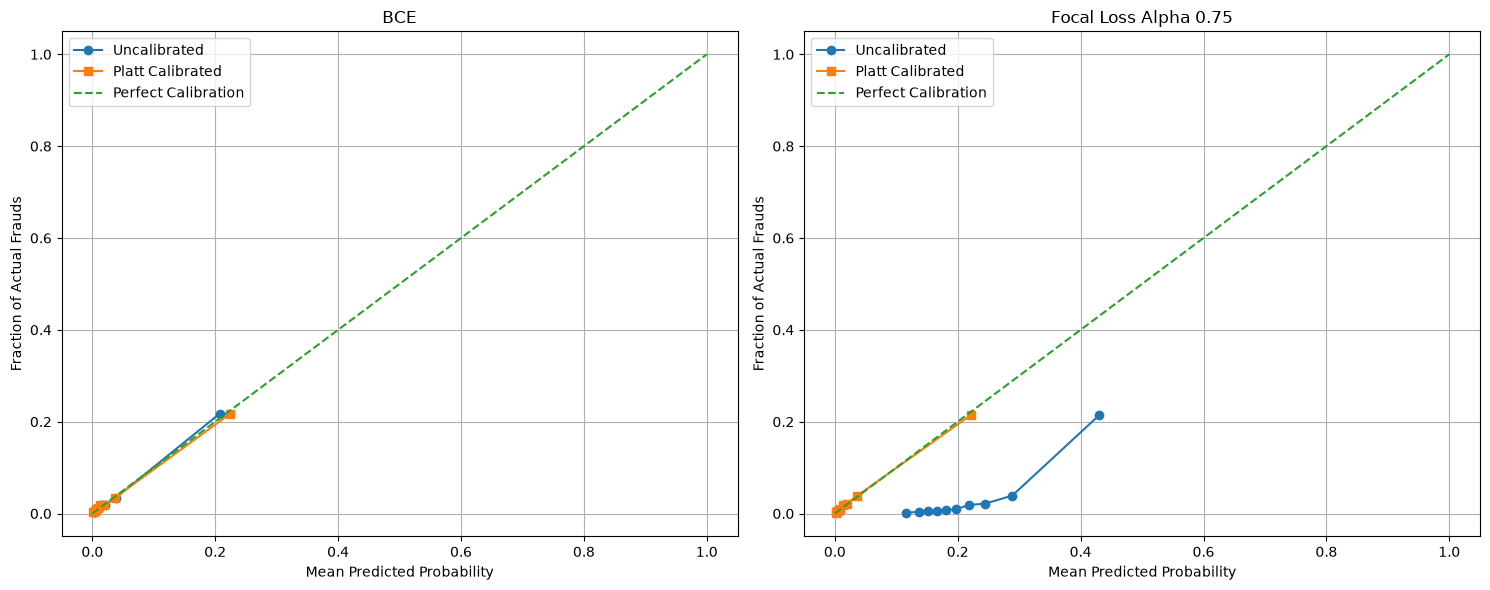

Reliability diagrams saved successfully.


In [30]:
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

models_to_plot = [
    (
        "BCE",
        bce_uncalibrated,
        bce_calibrated
    ),
    (
        "Focal Loss Alpha 0.75",
        focal_uncalibrated,
        focal_calibrated
    )
]

for ax, (model_name, raw_probs, calibrated_probs) in zip(
    axes, models_to_plot
):

    # Uncalibrated reliability
    raw_fraction, raw_mean = calibration_curve(
        y_eval,
        raw_probs,
        n_bins=10,
        strategy="quantile"
    )

    # Platt-calibrated reliability
    cal_fraction, cal_mean = calibration_curve(
        y_eval,
        calibrated_probs,
        n_bins=10,
        strategy="quantile"
    )

    ax.plot(
        raw_mean,
        raw_fraction,
        marker="o",
        label="Uncalibrated"
    )

    ax.plot(
        cal_mean,
        cal_fraction,
        marker="s",
        label="Platt Calibrated"
    )

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Perfect Calibration"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Mean Predicted Probability")
    ax.set_ylabel("Fraction of Actual Frauds")
    ax.legend()
    ax.grid(True)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "thursday_reliability_diagrams.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Reliability diagrams saved successfully.")

In [31]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Use the evaluation probabilities already generated
validation_probabilities = {
    "BCE": bce_uncalibrated,
    "Focal Alpha 0.75": focal_calibrated
}

thresholds = np.arange(0.05, 0.96, 0.01)

threshold_results = []

for model_name, probabilities in validation_probabilities.items():

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_eval,
            predictions,
            labels=[0, 1]
        ).ravel()

        threshold_results.append({
            "Model": model_name,
            "Threshold": round(threshold, 2),
            "Precision": precision_score(
                y_eval, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_eval, predictions, zero_division=0
            ),
            "F1 Score": f1_score(
                y_eval, predictions, zero_division=0
            ),
            "False Positives": fp,
            "False Negatives": fn,
            "True Positives": tp,
            "True Negatives": tn
        })

threshold_comparison = pd.DataFrame(threshold_results)

# Find the best F1 threshold for each model
best_thresholds = (
    threshold_comparison
    .loc[
        threshold_comparison.groupby("Model")["F1 Score"].idxmax()
    ]
    .reset_index(drop=True)
)

print("BEST THRESHOLDS BASED ON F1 SCORE")
display(best_thresholds.round(4))

# Save the complete threshold comparison
threshold_comparison.to_csv(
    RESULTS_DIR / "thursday_threshold_comparison.csv",
    index=False
)

best_thresholds.to_csv(
    RESULTS_DIR / "thursday_best_thresholds.csv",
    index=False
)

print("Threshold results saved successfully.")

BEST THRESHOLDS BASED ON F1 SCORE


,Model,Threshold,Precision,Recall,F1 Score,False Positives,False Negatives,True Positives,True Negatives
0,BCE,0.16,0.4179,0.4603,0.4381,929,782,667,41913
1,Focal Alpha 0.75,0.33,0.5973,0.3326,0.4273,325,967,482,42517


Threshold results saved successfully.


In [32]:
# Save the selected threshold summary

best_thresholds.to_csv(
    RESULTS_DIR / "thursday_selected_thresholds.csv",
    index=False
)

print("Selected thresholds saved.")
print("BCE threshold:", final_thresholds["BCE"])
print(
    "Focal threshold:",
    final_thresholds["Focal Alpha 0.75"]
)

Selected thresholds saved.


NameError: name 'final_thresholds' is not defined

In [33]:
# Display selected thresholds directly from best_thresholds

for _, row in best_thresholds.iterrows():
    print(
        f"{row['Model']} threshold: "
        f"{row['Threshold']:.2f}"
    )

print("\nSelected threshold file exists:",
      (RESULTS_DIR / "thursday_selected_thresholds.csv").exists())

BCE threshold: 0.16
Focal Alpha 0.75 threshold: 0.33

Selected threshold file exists: True


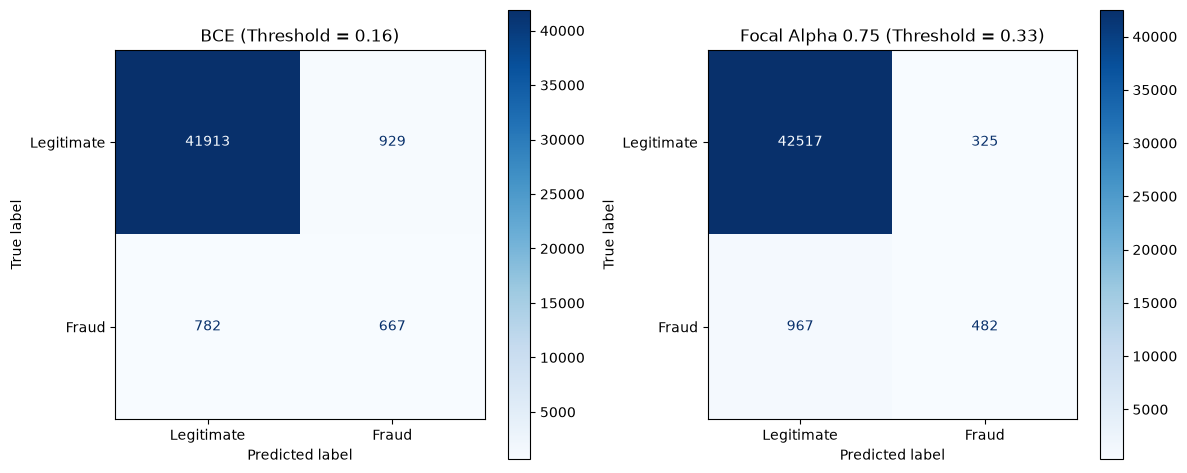

Confusion matrices saved successfully.


In [34]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

model_data = [
    ("BCE", bce_uncalibrated, 0.16),
    ("Focal Alpha 0.75", focal_calibrated, 0.33)
]

for ax, (name, probabilities, threshold) in zip(axes, model_data):

    predictions = (probabilities >= threshold).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_eval,
        predictions,
        labels=[0, 1],
        display_labels=["Legitimate", "Fraud"],
        cmap="Blues",
        values_format="d",
        ax=ax
    )

    ax.set_title(f"{name} (Threshold = {threshold})")

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "thursday_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrices saved successfully.")

In [35]:
# Generate predictions using selected thresholds

bce_predictions = (
    bce_uncalibrated >= 0.16
).astype(int)

focal_predictions = (
    focal_calibrated >= 0.33
).astype(int)

# Identify false negatives
bce_false_negative_mask = (
    (y_eval.to_numpy() == 1) &
    (bce_predictions == 0)
)

focal_false_negative_mask = (
    (y_eval.to_numpy() == 1) &
    (focal_predictions == 0)
)

# Extract false-negative transactions
bce_false_negatives = X_val.iloc[
    calibration_split:
].loc[bce_false_negative_mask].copy()

focal_false_negatives = X_val.iloc[
    calibration_split:
].loc[focal_false_negative_mask].copy()

print("BCE false negatives:", len(bce_false_negatives))
print("Focal false negatives:", len(focal_false_negatives))

print(
    "BCE false-negative dataset:",
    bce_false_negatives.shape
)

print(
    "Focal false-negative dataset:",
    focal_false_negatives.shape
)

BCE false negatives: 782
Focal false negatives: 967
BCE false-negative dataset: (782, 441)
Focal false-negative dataset: (967, 441)


In [36]:
# Create evaluation labels and transaction amount data

y_eval_array = y_eval.to_numpy()

evaluation_data = X_val.iloc[calibration_split:].copy()
evaluation_data["Actual_Fraud"] = y_eval_array
evaluation_data["BCE_Prediction"] = bce_predictions
evaluation_data["Focal_Prediction"] = focal_predictions

# Identify false negatives
bce_fn_data = evaluation_data[
    (evaluation_data["Actual_Fraud"] == 1) &
    (evaluation_data["BCE_Prediction"] == 0)
].copy()

focal_fn_data = evaluation_data[
    (evaluation_data["Actual_Fraud"] == 1) &
    (evaluation_data["Focal_Prediction"] == 0)
].copy()

# Analyze TransactionAmt
if "TransactionAmt" in evaluation_data.columns:

    amount_summary = pd.DataFrame({
        "All Fraud Transactions":
            evaluation_data.loc[
                evaluation_data["Actual_Fraud"] == 1,
                "TransactionAmt"
            ].describe(),

        "BCE False Negatives":
            bce_fn_data["TransactionAmt"].describe(),

        "Focal False Negatives":
            focal_fn_data["TransactionAmt"].describe()
    })

    display(amount_summary.round(2))

else:
    print("TransactionAmt column not found.")
    print("Available columns:", evaluation_data.columns.tolist())

,All Fraud Transactions,BCE False Negatives,Focal False Negatives
count,1449.00,782.00,967.00
mean,152.15,152.68,159.43
std,241.11,251.58,254.08
min,2.11,2.11,2.11
25%,38.98,48.20,46.57
50%,77.00,86.56,87.00
75%,161.00,171.00,171.00
max,3822.95,3822.95,3822.95


In [37]:
# Identify false-negative positions in the evaluation dataset

bce_fn_indices = set(
    np.where(bce_false_negative_mask)[0]
)

focal_fn_indices = set(
    np.where(focal_false_negative_mask)[0]
)

# Calculate overlap
common_fn = bce_fn_indices & focal_fn_indices

bce_only_fn = bce_fn_indices - focal_fn_indices

focal_only_fn = focal_fn_indices - bce_fn_indices

# Display results
overlap_results = pd.DataFrame({
    "Category": [
        "Common false negatives",
        "BCE-only false negatives",
        "Focal-only false negatives"
    ],
    "Count": [
        len(common_fn),
        len(bce_only_fn),
        len(focal_only_fn)
    ]
})

display(overlap_results)

print("\nVerification:")
print("BCE total:", len(bce_fn_indices))
print("Focal total:", len(focal_fn_indices))
print(
    "Common + BCE-only:",
    len(common_fn) + len(bce_only_fn)
)
print(
    "Common + Focal-only:",
    len(common_fn) + len(focal_only_fn)
)

,Category,Count
0,Common false negatives,782
1,BCE-only false negatives,0
2,Focal-only false negatives,185



Verification:
BCE total: 782
Focal total: 967
Common + BCE-only: 782
Common + Focal-only: 967


In [38]:
# Evaluation data with actual labels and model predictions

evaluation_analysis = X_val.iloc[calibration_split:].copy()

evaluation_analysis["Actual_Fraud"] = y_eval.to_numpy()
evaluation_analysis["BCE_Probability"] = bce_uncalibrated
evaluation_analysis["Focal_Probability"] = focal_calibrated

evaluation_analysis["BCE_Prediction"] = bce_predictions
evaluation_analysis["Focal_Prediction"] = focal_predictions

# Group 1: Missed by both
common_missed = evaluation_analysis[
    (evaluation_analysis["Actual_Fraud"] == 1) &
    (evaluation_analysis["BCE_Prediction"] == 0) &
    (evaluation_analysis["Focal_Prediction"] == 0)
].copy()

# Group 2: Caught by BCE but missed by Focal
bce_only_detected = evaluation_analysis[
    (evaluation_analysis["Actual_Fraud"] == 1) &
    (evaluation_analysis["BCE_Prediction"] == 1) &
    (evaluation_analysis["Focal_Prediction"] == 0)
].copy()

# Group 3: Detected by both
detected_by_both = evaluation_analysis[
    (evaluation_analysis["Actual_Fraud"] == 1) &
    (evaluation_analysis["BCE_Prediction"] == 1) &
    (evaluation_analysis["Focal_Prediction"] == 1)
].copy()

print("Missed by both:", len(common_missed))
print("Caught by BCE, missed by Focal:", len(bce_only_detected))
print("Detected by both:", len(detected_by_both))

Missed by both: 782
Caught by BCE, missed by Focal: 185
Detected by both: 482


In [39]:
groups = {
    "Missed by Both": common_missed,
    "BCE Only Detected": bce_only_detected,
    "Detected by Both": detected_by_both
}

group_summary = []

for group_name, group_data in groups.items():

    group_summary.append({
        "Group": group_name,
        "Count": len(group_data),
        "Mean Transaction Amount": group_data["TransactionAmt"].mean(),
        "Median Transaction Amount": group_data["TransactionAmt"].median(),
        "Mean BCE Probability": group_data["BCE_Probability"].mean(),
        "Mean Focal Probability": group_data["Focal_Probability"].mean()
    })

group_comparison = pd.DataFrame(group_summary)

display(group_comparison.round(4))

,Group,Count,Mean Transaction Amount,Median Transaction Amount,Mean BCE Probability,Mean Focal Probability
0,Missed by Both,782,152.6762,86.564,0.0525,0.0526
1,BCE Only Detected,185,187.9930,97.000,0.2290,0.2070
2,Detected by Both,482,137.5520,55.332,0.6784,0.7365


In [40]:
# Features identified in our earlier SHAP analysis

important_features = [
    "TransactionAmt",
    "P_emaildomain",
    "C1",
    "C13",
    "C5",
    "TransactionDT"
]

# Keep only features available in the evaluation dataset
important_features = [
    feature for feature in important_features
    if feature in evaluation_analysis.columns
]

groups = {
    "Missed by Both": common_missed,
    "BCE Only Detected": bce_only_detected,
    "Detected by Both": detected_by_both
}

feature_comparison = []

for group_name, group_data in groups.items():

    for feature in important_features:

        feature_comparison.append({
            "Group": group_name,
            "Feature": feature,
            "Mean": group_data[feature].mean(),
            "Median": group_data[feature].median(),
            "Missing Percentage": (
                group_data[feature].isna().mean() * 100
            )
        })

feature_comparison_df = pd.DataFrame(feature_comparison)

display(feature_comparison_df.round(4))

TypeError: 'Categorical' with dtype category does not support operation 'mean'

In [41]:
# Separate numerical and categorical features

important_features = [
    "TransactionAmt",
    "P_emaildomain",
    "C1",
    "C13",
    "C5",
    "TransactionDT"
]

groups = {
    "Missed by Both": common_missed,
    "BCE Only Detected": bce_only_detected,
    "Detected by Both": detected_by_both
}

feature_comparison = []

for group_name, group_data in groups.items():

    for feature in important_features:

        if feature not in group_data.columns:
            continue

        series = group_data[feature]

        if pd.api.types.is_numeric_dtype(series):

            feature_comparison.append({
                "Group": group_name,
                "Feature": feature,
                "Feature Type": "Numerical",
                "Mean": series.mean(),
                "Median": series.median(),
                "Missing Percentage": series.isna().mean() * 100,
                "Most Common Value": None
            })

        else:

            mode_values = series.mode(dropna=True)

            most_common = (
                mode_values.iloc[0]
                if not mode_values.empty
                else None
            )

            feature_comparison.append({
                "Group": group_name,
                "Feature": feature,
                "Feature Type": "Categorical",
                "Mean": None,
                "Median": None,
                "Missing Percentage": series.isna().mean() * 100,
                "Most Common Value": most_common
            })

feature_comparison_df = pd.DataFrame(feature_comparison)

display(feature_comparison_df.round(4))

,Group,Feature,Feature Type,Mean,Median,Missing Percentage,Most Common Value
0,Missed by Both,TransactionAmt,Numerical,1.526762e+02,8.656400e+01,0.0000,NaN
1,Missed by Both,P_emaildomain,Categorical,NaN,NaN,18.4143,gmail.com
2,Missed by Both,C1,Numerical,2.053840e+01,2.000000e+00,0.0000,NaN
3,Missed by Both,C13,Numerical,3.048980e+01,3.000000e+00,0.0000,NaN
4,Missed by Both,C5,Numerical,4.198200e+00,0.000000e+00,0.0000,NaN
5,Missed by Both,TransactionDT,Numerical,1.243359e+07,1.241439e+07,0.0000,NaN
6,BCE Only Detected,TransactionAmt,Numerical,1.879930e+02,9.700000e+01,0.0000,NaN
7,BCE Only Detected,P_emaildomain,Categorical,NaN,NaN,22.7027,gmail.com
8,BCE Only Detected,C1,Numerical,2.450270e+01,1.000000e+00,0.0000,NaN
9,BCE Only Detected,C13,Numerical,2.085950e+01,2.000000e+00,0.0000,NaN


In [42]:
feature_comparison_df.to_csv(
    RESULTS_DIR / "thursday_false_negative_feature_comparison.csv",
    index=False
)

print("Feature comparison saved successfully.")
print("Total comparisons:", len(feature_comparison_df))

Feature comparison saved successfully.
Total comparisons: 18


In [43]:
from scipy.stats import mannwhitneyu

numeric_features = [
    "TransactionAmt",
    "C1",
    "C13",
    "C5",
    "TransactionDT"
]

statistical_results = []

comparison_groups = [
    ("Missed by Both", common_missed,
     "BCE Only Detected", bce_only_detected),

    ("Missed by Both", common_missed,
     "Detected by Both", detected_by_both)
]

for group1_name, group1, group2_name, group2 in comparison_groups:

    for feature in numeric_features:

        values1 = group1[feature].dropna()
        values2 = group2[feature].dropna()

        statistic, p_value = mannwhitneyu(
            values1,
            values2,
            alternative="two-sided"
        )

        statistical_results.append({
            "Feature": feature,
            "Comparison": f"{group1_name} vs {group2_name}",
            "P-value": p_value,
            "Significant at 0.05": p_value < 0.05
        })

statistical_results_df = pd.DataFrame(statistical_results)

display(statistical_results_df.round(6))

,Feature,Comparison,P-value,Significant at 0.05
0,TransactionAmt,Missed by Both vs BCE Only Detected,0.290129,False
1,C1,Missed by Both vs BCE Only Detected,0.051016,False
2,C13,Missed by Both vs BCE Only Detected,0.000142,True
3,C5,Missed by Both vs BCE Only Detected,0.000000,True
4,TransactionDT,Missed by Both vs BCE Only Detected,0.836385,False
5,TransactionAmt,Missed by Both vs Detected by Both,0.000000,True
6,C1,Missed by Both vs Detected by Both,0.000000,True
7,C13,Missed by Both vs Detected by Both,0.000000,True
8,C5,Missed by Both vs Detected by Both,0.000000,True
9,TransactionDT,Missed by Both vs Detected by Both,0.898695,False


In [44]:
from statsmodels.stats.multitest import multipletests

# Apply Benjamini-Hochberg correction
reject, adjusted_p_values, _, _ = multipletests(
    statistical_results_df["P-value"],
    alpha=0.05,
    method="fdr_bh"
)

statistical_results_df["Adjusted P-value"] = adjusted_p_values
statistical_results_df["Significant After Correction"] = reject

display(
    statistical_results_df.sort_values(
        ["Comparison", "Adjusted P-value"]
    ).round(8)
)

# Save corrected statistical results
statistical_results_df.to_csv(
    RESULTS_DIR / "thursday_false_negative_statistical_tests.csv",
    index=False
)

print("Multiple-testing corrected results saved.")

,Feature,Comparison,P-value,Significant at 0.05,Adjusted P-value,Significant After Correction
3,C5,Missed by Both vs BCE Only Detected,0.000000e+00,True,0.000000e+00,True
2,C13,Missed by Both vs BCE Only Detected,1.415300e-04,True,2.358800e-04,True
1,C1,Missed by Both vs BCE Only Detected,5.101644e-02,False,7.288062e-02,False
0,TransactionAmt,Missed by Both vs BCE Only Detected,2.901294e-01,False,3.626618e-01,False
4,TransactionDT,Missed by Both vs BCE Only Detected,8.363853e-01,False,8.986948e-01,False
6,C1,Missed by Both vs Detected by Both,0.000000e+00,True,0.000000e+00,True
7,C13,Missed by Both vs Detected by Both,0.000000e+00,True,0.000000e+00,True
8,C5,Missed by Both vs Detected by Both,0.000000e+00,True,0.000000e+00,True
5,TransactionAmt,Missed by Both vs Detected by Both,2.400000e-07,True,4.800000e-07,True
9,TransactionDT,Missed by Both vs Detected by Both,8.986948e-01,False,8.986948e-01,False


Multiple-testing corrected results saved.


In [45]:
# Verify Thursday analysis files

files_to_verify = [
    "thursday_calibration_evaluation.csv",
    "thursday_reliability_diagrams.png",
    "thursday_threshold_comparison.csv",
    "thursday_best_thresholds.csv",
    "thursday_selected_thresholds.csv",
    "thursday_confusion_matrices.png",
    "thursday_false_negative_feature_comparison.csv",
    "thursday_false_negative_statistical_tests.csv"
]

for filename in files_to_verify:

    file_path = RESULTS_DIR / filename

    print(
        f"{filename}: "
        f"{'EXISTS' if file_path.exists() else 'MISSING'}"
    )

thursday_calibration_evaluation.csv: EXISTS
thursday_reliability_diagrams.png: EXISTS
thursday_threshold_comparison.csv: EXISTS
thursday_best_thresholds.csv: EXISTS
thursday_selected_thresholds.csv: EXISTS
thursday_confusion_matrices.png: EXISTS
thursday_false_negative_feature_comparison.csv: EXISTS
thursday_false_negative_statistical_tests.csv: EXISTS


In [46]:
# Check training and evaluation datasets

print("TRAINING DATA")
print("X_train available:", "X_train" in globals())
print("y_train available:", "y_train" in globals())

if "X_train" in globals():
    print("X_train shape:", X_train.shape)

if "y_train" in globals():
    print("y_train shape:", y_train.shape)

print("\nVALIDATION DATA")
print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

print("\nTEST DATA")
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nSAVED TRAINING DATA")
print(
    "X_train.pkl exists:",
    (RESULTS_DIR / "X_train.pkl").exists()
)

print(
    "y_train.pkl exists:",
    (RESULTS_DIR / "y_train.pkl").exists()
)

TRAINING DATA
X_train available: False
y_train available: False

VALIDATION DATA
X_val shape: (88581, 441)
y_val shape: (88581,)

TEST DATA
X_test shape: (88581, 441)
y_test shape: (88581,)

SAVED TRAINING DATA
X_train.pkl exists: False
y_train.pkl exists: False


In [47]:

from pathlib import Path
import json

PROJECT_DIR = Path(r"D:\Fraud-Detection")
NOTEBOOKS_DIR = PROJECT_DIR / "notebooks"
RESULTS_DIR = PROJECT_DIR / "results"
MODELS_DIR = PROJECT_DIR / "models"

notebook_path = NOTEBOOKS_DIR / "02_Advanced_Implementation.ipynb"

print("Notebook exists:", notebook_path.exists())
print("Project directory:", PROJECT_DIR)

Notebook exists: True
Project directory: D:\Fraud-Detection


In [48]:
with open(notebook_path, "r", encoding="utf-8") as file:
    notebook_data = json.load(file)

keywords = [
    "X_train",
    "y_train",
    "train_test_split",
    "chronological",
    "sort_values",
    "413378",
    "train_transaction"
]

for cell_number, cell in enumerate(notebook_data["cells"]):

    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if any(keyword.lower() in source.lower() for keyword in keywords):

        print("\n" + "=" * 75)
        print("CELL:", cell_number)
        print("=" * 75)
        print(source)


CELL: 6
# Load the original training datasets

train_transaction = pd.read_csv(
    os.path.join(RAW_DIR, "train_transaction.csv")
)

train_identity = pd.read_csv(
    os.path.join(RAW_DIR, "train_identity.csv")
)

print("Transaction shape:", train_transaction.shape)
print("Identity shape:", train_identity.shape)

# Merge datasets exactly as Tuesday

train = train_transaction.merge(
    train_identity,
    on="TransactionID",
    how="left"
)

print("Merged dataset:", train.shape)

# Recreate Tuesday's chronological split

train_sorted = train.sort_values(
    by="TransactionDT"
).reset_index(drop=True)

total_rows = len(train_sorted)

train_end = int(total_rows * 0.70)
val_end = int(total_rows * 0.85)

train_set = train_sorted.iloc[:train_end].copy()
val_set = train_sorted.iloc[train_end:val_end].copy()
test_set = train_sorted.iloc[val_end:].copy()

print("\nChronological split completed!")

print("Training:", train_set.shape)
print("Validation:", val_set.shape)
print("Testing:", tes

In [49]:
# Inspect the original notebook's feature engineering and training cells

for cell_number in range(16, 32):

    cell = notebook_data["cells"][cell_number]

    if cell["cell_type"] in ["code", "markdown"]:

        source = "".join(cell["source"])

        if source.strip():
            print("\n" + "=" * 75)
            print("CELL:", cell_number)
            print("=" * 75)
            print(source)


CELL: 16

# Create missingness indicators for shifted features

features_to_track = ["id_31", "id_13"]

for feature in features_to_track:
    missing_feature = feature + "_is_missing"

    X_train[missing_feature] = X_train[feature].isna().astype("int8")
    X_val[missing_feature] = X_val[feature].isna().astype("int8")
    X_test[missing_feature] = X_test[feature].isna().astype("int8")


# Verify the new features
print("Missingness indicators created!\n")

for feature in features_to_track:
    missing_feature = feature + "_is_missing"

    print(missing_feature)
    print("Training missing rate:", X_train[missing_feature].mean().round(4))
    print("Validation missing rate:", X_val[missing_feature].mean().round(4))
    print("Testing missing rate:", X_test[missing_feature].mean().round(4))
    print()

print("Updated feature dimensions:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)


CELL: 17

# Create time-based features using t

In [50]:
import pandas as pd
import numpy as np
import os

RAW_DIR = PROJECT_DIR / "data" / "raw"

# Load original datasets
train_transaction = pd.read_csv(
    RAW_DIR / "train_transaction.csv"
)

train_identity = pd.read_csv(
    RAW_DIR / "train_identity.csv"
)

print("Transaction dataset:", train_transaction.shape)
print("Identity dataset:", train_identity.shape)

# Merge exactly as in Notebook 02
train = train_transaction.merge(
    train_identity,
    on="TransactionID",
    how="left"
)

print("Merged dataset:", train.shape)

# Sort chronologically
train_sorted = train.sort_values(
    by="TransactionDT"
).reset_index(drop=True)

# Recreate original 70/15/15 split
total_rows = len(train_sorted)

train_end = int(total_rows * 0.70)
val_end = int(total_rows * 0.85)

train_set = train_sorted.iloc[:train_end].copy()
val_set = train_sorted.iloc[train_end:val_end].copy()
test_set = train_sorted.iloc[val_end:].copy()

print("\nCHRONOLOGICAL SPLIT")
print("Training:", train_set.shape)
print("Validation:", val_set.shape)
print("Testing:", test_set.shape)

print("\nTime boundaries:")
for name, dataset in [
    ("Training", train_set),
    ("Validation", val_set),
    ("Testing", test_set)
]:
    print(
        name,
        dataset["TransactionDT"].min(),
        "to",
        dataset["TransactionDT"].max()
    )

Transaction dataset: (590540, 394)
Identity dataset: (144233, 41)
Merged dataset: (590540, 434)


MemoryError: Unable to allocate 1.23 GiB for an array with shape (399, 413378) and data type float64

In [51]:
import gc

# Remove temporary datasets if they exist
for name in [
    "train_sorted",
    "train",
    "train_transaction",
    "train_identity"
]:
    if name in globals():
        del globals()[name]

gc.collect()

print("Memory cleanup completed.")

Memory cleanup completed.


In [52]:
# Reload original datasets
train_transaction = pd.read_csv(
    RAW_DIR / "train_transaction.csv"
)

train_identity = pd.read_csv(
    RAW_DIR / "train_identity.csv"
)

# Merge and sort
train = train_transaction.merge(
    train_identity,
    on="TransactionID",
    how="left"
)

train.sort_values(
    "TransactionDT",
    inplace=True
)

train.reset_index(drop=True, inplace=True)

# Split boundaries
total_rows = len(train)

train_end = int(total_rows * 0.70)
val_end = int(total_rows * 0.85)

print("Total rows:", total_rows)
print("Training rows:", train_end)
print("Validation rows:", val_end - train_end)
print("Testing rows:", total_rows - val_end)

MemoryError: Unable to allocate 16.0 KiB for an array with shape (2048,) and data type float64

In [53]:
# Separate labels
y_train_rebuilt = train.iloc[:train_end]["isFraud"].copy()
y_val_rebuilt = train.iloc[train_end:val_end]["isFraud"].copy()
y_test_rebuilt = train.iloc[val_end:]["isFraud"].copy()

# Create feature datasets
X_train_rebuilt = train.iloc[:train_end].drop(
    columns=["isFraud", "TransactionID"]
).copy()

X_val_rebuilt = train.iloc[train_end:val_end].drop(
    columns=["isFraud", "TransactionID"]
).copy()

X_test_rebuilt = train.iloc[val_end:].drop(
    columns=["isFraud", "TransactionID"]
).copy()

print("Training:", X_train_rebuilt.shape)
print("Validation:", X_val_rebuilt.shape)
print("Testing:", X_test_rebuilt.shape)

NameError: name 'train' is not defined

In [1]:
from pathlib import Path
import gc
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

PROJECT_DIR = Path(r"D:\Fraud-Detection")
DATA_DIR = PROJECT_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
MODELS_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"

bce_model = joblib.load(MODELS_DIR / "bce_model.pkl")

X_val = joblib.load(RESULTS_DIR / "X_val.pkl")
y_val = joblib.load(RESULTS_DIR / "y_val.pkl")

X_test = joblib.load(RESULTS_DIR / "X_test.pkl")
y_test = joblib.load(RESULTS_DIR / "y_test.pkl")

gc.collect()

print("Validation:", X_val.shape)
print("Test:", X_test.shape)
print("BCE model loaded:", bce_model is not None)

Validation: (88581, 441)
Test: (88581, 441)
BCE model loaded: True


In [2]:
try:
    import pyarrow
    print("PyArrow available:", pyarrow.__version__)
except ImportError:
    print("PyArrow is not installed.")

PyArrow is not installed.


In [3]:
import psutil
import importlib.util

memory = psutil.virtual_memory()

print("Total RAM:", round(memory.total / (1024**3), 2), "GB")
print("Available RAM:", round(memory.available / (1024**3), 2), "GB")
print("Currently used:", round(memory.percent, 2), "%")

print("\nAvailable libraries:")
print("Polars:", importlib.util.find_spec("polars") is not None)
print("DuckDB:", importlib.util.find_spec("duckdb") is not None)
print("PyArrow:", importlib.util.find_spec("pyarrow") is not None)

Total RAM: 15.82 GB
Available RAM: 6.49 GB
Currently used: 59.0 %

Available libraries:
Polars: False
DuckDB: False
PyArrow: False


In [4]:
%pip install polars

   ---------------------------------------- 0.0/911.5 kB ? eta -:--:--
   ----------- ---------------------------- 262.1/911.5 kB ? eta -:--:--
   ----------------------- ---------------- 524.3/911.5 kB 2.1 MB/s eta 0:00:01
   ---------------------------------------- 911.5/911.5 kB 2.2 MB/s  0:00:00
   ---------------------------------------- 0.0/53.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/53.9 MB 3.2 MB/s eta 0:00:17
    --------------------------------------- 1.0/53.9 MB 3.1 MB/s eta 0:00:18
   - -------------------------------------- 1.8/53.9 MB 3.5 MB/s eta 0:00:15
   -- ------------------------------------- 3.1/53.9 MB 4.0 MB/s eta 0:00:13
   --- ------------------------------------ 4.2/53.9 MB 4.3 MB/s eta 0:00:12
   ---- ----------------------------------- 5.8/53.9 MB 4.9 MB/s eta 0:00:10
   ----- ---------------------------------- 7.6/53.9 MB 5.5 MB/s eta 0:00:09
   ------- -------------------------------- 9.7/53.9 MB 6.2 MB/s eta 0:00:08
   -------- -

In [1]:
import polars as pl
import psutil

print("Polars version:", pl.__version__)
print(
    "Available RAM:",
    round(psutil.virtual_memory().available / (1024**3), 2),
    "GB"
)

Polars version: 2.1.0
Available RAM: 7.11 GB


In [2]:
from pathlib import Path
import polars as pl
import psutil
import shutil

PROJECT_DIR = Path(r"D:\Fraud-Detection")
RAW_DIR = PROJECT_DIR / "data" / "raw"
RESULTS_DIR = PROJECT_DIR / "results"
MODELS_DIR = PROJECT_DIR / "models"

transaction_path = RAW_DIR / "train_transaction.csv"
identity_path = RAW_DIR / "train_identity.csv"

print("Transaction file exists:", transaction_path.exists())
print("Identity file exists:", identity_path.exists())

if transaction_path.exists():
    print(
        "Transaction file size:",
        round(transaction_path.stat().st_size / (1024**3), 2),
        "GB"
    )

if identity_path.exists():
    print(
        "Identity file size:",
        round(identity_path.stat().st_size / (1024**3), 2),
        "GB"
    )

disk = shutil.disk_usage(PROJECT_DIR)

print("\nAvailable disk space:",
      round(disk.free / (1024**3), 2), "GB")

print("Available RAM:",
      round(psutil.virtual_memory().available / (1024**3), 2), "GB")

Transaction file exists: True
Identity file exists: True
Transaction file size: 0.64 GB
Identity file size: 0.02 GB

Available disk space: 141.93 GB
Available RAM: 7.07 GB


In [3]:
import polars as pl
from pathlib import Path

# Read CSV files lazily
transaction_lf = pl.scan_csv(
    transaction_path,
    infer_schema_length=10000
)

identity_lf = pl.scan_csv(
    identity_path,
    infer_schema_length=10000
)

print("Transaction schema:")
print(transaction_lf.collect_schema())

print("\nIdentity schema:")
print(identity_lf.collect_schema())

Transaction schema:
Schema({'TransactionID': Int64, 'isFraud': Int64, 'TransactionDT': Int64, 'TransactionAmt': Float64, 'ProductCD': String, 'card1': Int64, 'card2': Float64, 'card3': Float64, 'card4': String, 'card5': Float64, 'card6': String, 'addr1': Float64, 'addr2': Float64, 'dist1': Float64, 'dist2': Float64, 'P_emaildomain': String, 'R_emaildomain': String, 'C1': Float64, 'C2': Float64, 'C3': Float64, 'C4': Float64, 'C5': Float64, 'C6': Float64, 'C7': Float64, 'C8': Float64, 'C9': Float64, 'C10': Float64, 'C11': Float64, 'C12': Float64, 'C13': Float64, 'C14': Float64, 'D1': Float64, 'D2': Float64, 'D3': Float64, 'D4': Float64, 'D5': Float64, 'D6': Float64, 'D7': Float64, 'D8': Float64, 'D9': Float64, 'D10': Float64, 'D11': Float64, 'D12': Float64, 'D13': Float64, 'D14': Float64, 'D15': Float64, 'M1': String, 'M2': String, 'M3': String, 'M4': String, 'M5': String, 'M6': String, 'M7': String, 'M8': String, 'M9': String, 'V1': Float64, 'V2': Float64, 'V3': Float64, 'V4': Float64, 

In [4]:
merged_parquet_path = RESULTS_DIR / "reconstruction_merged_sorted.parquet"

if merged_parquet_path.exists():
    raise FileExistsError(
        f"File already exists: {merged_parquet_path}\n"
        "Stopping to avoid overwriting it."
    )

merged_lf = (
    transaction_lf
    .join(
        identity_lf,
        on="TransactionID",
        how="left"
    )
    .sort("TransactionDT")
)

print("Starting chronological merge and sort...")

merged_lf.sink_parquet(
    merged_parquet_path,
    compression="zstd",
    engine="streaming"
)

print("\nMerge and sort completed!")
print("Saved to:", merged_parquet_path)
print(
    "File size:",
    round(merged_parquet_path.stat().st_size / (1024**3), 2),
    "GB"
)

Starting chronological merge and sort...

Merge and sort completed!
Saved to: D:\Fraud-Detection\results\reconstruction_merged_sorted.parquet
File size: 0.07 GB


In [5]:
merged_check = pl.scan_parquet(merged_parquet_path)

print("Rows:", merged_check.select(pl.len()).collect().item())
print("Columns:", len(merged_check.collect_schema()))

print("\nChronological verification:")

time_check = merged_check.select([
    pl.col("TransactionDT").min().alias("minimum"),
    pl.col("TransactionDT").max().alias("maximum"),
    pl.col("TransactionDT").is_sorted().alias("sorted")
]).collect()

print(time_check)

Rows: 590540
Columns: 434

Chronological verification:
shape: (1, 3)
┌─────────┬──────────┬────────┐
│ minimum ┆ maximum  ┆ sorted │
│ ---     ┆ ---      ┆ ---    │
│ i64     ┆ i64      ┆ bool   │
╞═════════╪══════════╪════════╡
│ 86400   ┆ 15811131 ┆ true   │
└─────────┴──────────┴────────┘


In [6]:
total_rows = 590540

train_end = int(total_rows * 0.70)
val_end = int(total_rows * 0.85)

train_parquet = RESULTS_DIR / "reconstruction_train.parquet"
val_parquet = RESULTS_DIR / "reconstruction_val.parquet"
test_parquet = RESULTS_DIR / "reconstruction_test.parquet"

output_files = [train_parquet, val_parquet, test_parquet]

existing = [p for p in output_files if p.exists()]

if existing:
    raise FileExistsError(
        f"These files already exist: {existing}"
    )

merged_lf = pl.scan_parquet(merged_parquet_path)

print("Creating training partition...")
merged_lf.slice(0, train_end).sink_parquet(train_parquet)

print("Creating validation partition...")
merged_lf.slice(
    train_end, val_end - train_end
).sink_parquet(val_parquet)

print("Creating test partition...")
merged_lf.slice(
    val_end, total_rows - val_end
).sink_parquet(test_parquet)

print("\nPartitions saved successfully.")

Creating training partition...
Creating validation partition...
Creating test partition...

Partitions saved successfully.


In [7]:
for name, path in [
    ("Training", train_parquet),
    ("Validation", val_parquet),
    ("Testing", test_parquet)
]:
    count = pl.scan_parquet(path).select(
        pl.len()
    ).collect().item()

    print(
        f"{name}: {count:,} rows | "
        f"{path.stat().st_size / (1024**2):.2f} MB"
    )

Training: 413,378 rows | 51.38 MB
Validation: 88,581 rows | 10.95 MB
Testing: 88,581 rows | 11.48 MB


In [8]:
%pip install pyarrow

   ---------------------------------------- 0.0/29.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/29.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/29.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/29.0 MB ? eta -:--:--
   - -------------------------------------- 1.0/29.0 MB 2.3 MB/s eta 0:00:12
   -- ------------------------------------- 1.8/29.0 MB 3.0 MB/s eta 0:00:10
   --- ------------------------------------ 2.6/29.0 MB 3.2 MB/s eta 0:00:09
   ---- ----------------------------------- 3.4/29.0 MB 3.3 MB/s eta 0:00:08
   ------ --------------------------------- 4.7/29.0 MB 3.8 MB/s eta 0:00:07
   -------- ------------------------------- 6.3/29.0 MB 4.3 MB/s eta 0:00:06
   ---------- ----------------------------- 7.3/29.0 MB 4.5 MB/s eta 0:00:05
   ------------ --------------------------- 9.2/29.0 MB 4.9 MB/s eta 0:00:05
   --------------- ------------------------ 11.3/29.0 MB 5.5 MB/s eta 0:00:04
   ------------------ ----

In [1]:
import polars as pl
import pyarrow as pa
import pandas as pd
import joblib
import numpy as np
from pathlib import Path

PROJECT_DIR = Path(r"D:\Fraud-Detection")
RESULTS_DIR = PROJECT_DIR / "results"
MODELS_DIR = PROJECT_DIR / "models"

train_parquet = RESULTS_DIR / "reconstruction_train.parquet"
val_parquet = RESULTS_DIR / "reconstruction_val.parquet"
test_parquet = RESULTS_DIR / "reconstruction_test.parquet"

X_val = joblib.load(RESULTS_DIR / "X_val.pkl")
y_val = joblib.load(RESULTS_DIR / "y_val.pkl")

X_test = joblib.load(RESULTS_DIR / "X_test.pkl")
y_test = joblib.load(RESULTS_DIR / "y_test.pkl")

print("PyArrow:", pa.__version__)
print("Polars:", pl.__version__)
print("Saved validation:", X_val.shape)
print("Saved test:", X_test.shape)
print("Training partition exists:", train_parquet.exists())

PyArrow: 26.0.1
Polars: 2.1.0
Saved validation: (88581, 441)
Saved test: (88581, 441)
Training partition exists: True


In [2]:
import gc
import pandas as pd
import numpy as np
import polars as pl
import joblib

# Release previously loaded evaluation datasets
for name in ["X_val", "y_val", "X_test", "y_test"]:
    if name in globals():
        del globals()[name]

gc.collect()

print("Available RAM after cleanup:")
import psutil
print(round(
    psutil.virtual_memory().available / (1024**3), 2
), "GB")

Available RAM after cleanup:
7.14 GB


In [3]:
# Load only the training partition
train_pd = pl.read_parquet(train_parquet).to_pandas()

print("Training partition loaded:", train_pd.shape)
print("Fraud rate:", train_pd["isFraud"].mean())
print("First transaction time:", train_pd["TransactionDT"].min())
print("Last transaction time:", train_pd["TransactionDT"].max())

Training partition loaded: (413378, 434)
Fraud rate: 0.03516878014795175
First transaction time: 86400
Last transaction time: 10437996


In [4]:
# Separate target
y_train_rebuilt = train_pd["isFraud"].copy()

# Remove target and TransactionID from model features
X_train_rebuilt = train_pd.drop(
    columns=["isFraud", "TransactionID"]
).copy()

# Identify categorical columns
categorical_columns = X_train_rebuilt.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Convert training categorical columns to category dtype
for col in categorical_columns:
    X_train_rebuilt[col] = X_train_rebuilt[col].astype("category")

print("Training features:", X_train_rebuilt.shape)
print("Training labels:", y_train_rebuilt.shape)

print("\nCategorical columns:", len(categorical_columns))
print(categorical_columns)

print("\nTraining fraud rate:", y_train_rebuilt.mean())

print("\nData types:")
print(X_train_rebuilt.dtypes.value_counts())

C:\Users\prana\AppData\Local\Temp\ipykernel_20712\3481009669.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train_rebuilt.select_dtypes(


Training features: (413378, 432)
Training labels: (413378,)

Categorical columns: 31
['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'id_12', 'id_15', 'id_16', 'id_23', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType', 'DeviceInfo']

Training fraud rate: 0.03516878014795175

Data types:
float64     399
category     12
category      4
int64         2
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
Name: count, dtype: int64


In [5]:
features_to_track = ["id_31", "id_13"]

for feature in features_to_track:
    missing_feature = feature + "_is_missing"

    X_train_rebuilt[missing_feature] = (
        X_train_rebuilt[feature].isna().astype("int8")
    )

print("Missingness indicators created.")

for feature in features_to_track:
    missing_feature = feature + "_is_missing"

    print(
        missing_feature,
        "| Missing rate:",
        round(X_train_rebuilt[missing_feature].mean(), 4)
    )

print("\nUpdated shape:", X_train_rebuilt.shape)

Missingness indicators created.
id_31_is_missing | Missing rate: 0.7406
id_13_is_missing | Missing rate: 0.7692

Updated shape: (413378, 434)


In [6]:
def create_time_features(dataset):
    transaction_dt = dataset["TransactionDT"]

    features = pd.DataFrame(index=dataset.index)

    features["transaction_day"] = (
        transaction_dt // 86400
    ).astype("int32")

    transaction_hour = (
        (transaction_dt % 86400) // 3600
    ).astype("int8")

    features["transaction_hour"] = transaction_hour

    features["transaction_hour_sin"] = np.sin(
        2 * np.pi * transaction_hour / 24
    )

    features["transaction_hour_cos"] = np.cos(
        2 * np.pi * transaction_hour / 24
    )

    return features


time_train = create_time_features(train_pd)

X_train_rebuilt = pd.concat(
    [X_train_rebuilt, time_train],
    axis=1
)

print("Time features created.")
print(time_train.head())

print("\nUpdated training dimensions:", X_train_rebuilt.shape)

Time features created.
   transaction_day  transaction_hour  transaction_hour_sin  \
0                1                 0                   0.0   
1                1                 0                   0.0   
2                1                 0                   0.0   
3                1                 0                   0.0   
4                1                 0                   0.0   

   transaction_hour_cos  
0                   1.0  
1                   1.0  
2                   1.0  
3                   1.0  
4                   1.0  

Updated training dimensions: (413378, 438)


In [7]:
def create_historical_features(data):
    result = pd.DataFrame(index=data.index)

    card_count = {}
    card_amount_sum = {}
    address_count = {}

    card1_counts = []
    card1_amount_means = []
    addr1_counts = []

    for card, address, amount in data[
        ["card1", "addr1", "TransactionAmt"]
    ].itertuples(index=False, name=None):

        # Card history before current transaction
        previous_count = card_count.get(card, 0)
        previous_sum = card_amount_sum.get(card, 0.0)

        card1_counts.append(previous_count)

        if previous_count > 0:
            card1_amount_means.append(
                previous_sum / previous_count
            )
        else:
            card1_amount_means.append(np.nan)

        # Address history before current transaction
        addr1_counts.append(
            address_count.get(address, 0)
        )

        # Update history after calculating features
        card_count[card] = previous_count + 1
        card_amount_sum[card] = previous_sum + amount

        address_count[address] = (
            address_count.get(address, 0) + 1
        )

    result["card1_prev_count"] = card1_counts
    result["card1_prev_amount_mean"] = card1_amount_means
    result["addr1_prev_count"] = addr1_counts

    return result


historical_train = create_historical_features(train_pd)

print("Historical feature generation completed!")
print("Shape:", historical_train.shape)

print("\nFirst 10 historical records:")
print(historical_train.head(10))

print("\nMissing values:")
print(historical_train.isna().sum())

print("\nNegative historical counts:")
print(
    (historical_train[
        ["card1_prev_count", "addr1_prev_count"]
    ] < 0).sum()
)

Historical feature generation completed!
Shape: (413378, 3)

First 10 historical records:
   card1_prev_count  card1_prev_amount_mean  addr1_prev_count
0                 0                     NaN                 0
1                 0                     NaN                 0
2                 0                     NaN                 0
3                 0                     NaN                 0
4                 0                     NaN                 0
5                 0                     NaN                 0
6                 0                     NaN                 0
7                 0                     NaN                 1
8                 0                     NaN                 0
9                 0                     NaN                 0

Missing values:
card1_prev_count              0
card1_prev_amount_mean    12242
addr1_prev_count              0
dtype: int64

Negative historical counts:
card1_prev_count    0
addr1_prev_count    0
dtype: int64


In [8]:
# Append the three historical features
X_train_rebuilt = pd.concat(
    [X_train_rebuilt, historical_train],
    axis=1
)

print("Reconstructed training features:", X_train_rebuilt.shape)
print("Training labels:", y_train_rebuilt.shape)

print("\nDuplicate columns:", X_train_rebuilt.columns.duplicated().sum())
print("Missing historical amount values:",
      X_train_rebuilt["card1_prev_amount_mean"].isna().sum())

assert X_train_rebuilt.shape == (413378, 441)
assert X_train_rebuilt.columns.is_unique

print("\nTraining feature assembly verified!")

Reconstructed training features: (413378, 441)
Training labels: (413378,)

Duplicate columns: 0
Missing historical amount values: 12242

Training feature assembly verified!


In [9]:
# Rebuild historical state after processing training transactions
card_count = {}
card_amount_sum = {}
address_count = {}

for card, address, amount in train_pd[
    ["card1", "addr1", "TransactionAmt"]
].itertuples(index=False, name=None):

    previous_count = card_count.get(card, 0)
    previous_sum = card_amount_sum.get(card, 0.0)

    card_count[card] = previous_count + 1
    card_amount_sum[card] = previous_sum + amount

    address_count[address] = (
        address_count.get(address, 0) + 1
    )

print("Historical state carried forward.")
print("Unique card keys:", len(card_count))
print("Unique address keys:", len(address_count))

Historical state carried forward.
Unique card keys: 12242
Unique address keys: 47836


In [10]:
# Load only validation partition
val_pd = pl.read_parquet(val_parquet).to_pandas()

# Separate target
y_val_rebuilt = val_pd["isFraud"].copy()

# Create base features
X_val_rebuilt = val_pd.drop(
    columns=["isFraud", "TransactionID"]
).copy()

# Apply training categorical categories
for col in categorical_columns:
    X_val_rebuilt[col] = pd.Categorical(
        X_val_rebuilt[col],
        categories=X_train_rebuilt[col].cat.categories
    )

print("Validation loaded:", X_val_rebuilt.shape)
print("Validation labels:", y_val_rebuilt.shape)

print("Validation fraud rate:", y_val_rebuilt.mean())

Validation loaded: (88581, 432)
Validation labels: (88581,)
Validation fraud rate: 0.03434145019812375


C:\Users\prana\AppData\Local\Temp\ipykernel_20712\39462844.py:14: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X_val_rebuilt[col] = pd.Categorical(
C:\Users\prana\AppData\Local\Temp\ipykernel_20712\39462844.py:14: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X_val_rebuilt[col] = pd.Categorical(
C:\Users\prana\AppData\Local\Temp\ipykernel_20712\39462844.py:14: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X_val_rebuilt[col] = pd.Categorical(
C:\Users\prana\AppData\Local\Temp\ipykernel_20712\39462844.py:14: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entr

In [11]:
# Missingness indicators
for feature in ["id_31", "id_13"]:
    X_val_rebuilt[feature + "_is_missing"] = (
        X_val_rebuilt[feature].isna().astype("int8")
    )

# Time features
time_val = create_time_features(val_pd)

X_val_rebuilt = pd.concat(
    [X_val_rebuilt, time_val],
    axis=1
)

print("Validation dimensions:", X_val_rebuilt.shape)

Validation dimensions: (88581, 438)


In [12]:
def create_historical_features_from_state(data, card_count,
                                          card_amount_sum,
                                          address_count):

    result = pd.DataFrame(index=data.index)

    card1_counts = []
    card1_amount_means = []
    addr1_counts = []

    for card, address, amount in data[
        ["card1", "addr1", "TransactionAmt"]
    ].itertuples(index=False, name=None):

        previous_count = card_count.get(card, 0)
        previous_sum = card_amount_sum.get(card, 0.0)

        card1_counts.append(previous_count)

        if previous_count > 0:
            card1_amount_means.append(
                previous_sum / previous_count
            )
        else:
            card1_amount_means.append(np.nan)

        addr1_counts.append(
            address_count.get(address, 0)
        )

        card_count[card] = previous_count + 1
        card_amount_sum[card] = previous_sum + amount
        address_count[address] = address_count.get(address, 0) + 1

    result["card1_prev_count"] = card1_counts
    result["card1_prev_amount_mean"] = card1_amount_means
    result["addr1_prev_count"] = addr1_counts

    return result


historical_val = create_historical_features_from_state(
    val_pd,
    card_count,
    card_amount_sum,
    address_count
)

X_val_rebuilt = pd.concat(
    [X_val_rebuilt, historical_val],
    axis=1
)

print("Reconstructed validation:", X_val_rebuilt.shape)
print("Expected validation:", (88581, 441))

Reconstructed validation: (88581, 441)
Expected validation: (88581, 441)


In [13]:
# Load the original saved validation dataset
X_val_original = joblib.load(RESULTS_DIR / "X_val.pkl")
y_val_original = joblib.load(RESULTS_DIR / "y_val.pkl")

# Reset indexes because the reconstructed partition has a local index
original = X_val_original.reset_index(drop=True)
rebuilt = X_val_rebuilt.reset_index(drop=True)

print("Original shape:", original.shape)
print("Rebuilt shape:", rebuilt.shape)

# Check column order
print("\nColumn order identical:",
      original.columns.tolist() == rebuilt.columns.tolist())

# Compare feature values
comparison_results = []

for col in original.columns:

    a = original[col]
    b = rebuilt[col]

    if isinstance(a.dtype, pd.CategoricalDtype):
        equal = (
            a.astype("object")
            .fillna("__MISSING__")
            .equals(
                b.astype("object").fillna("__MISSING__")
            )
        )

    elif pd.api.types.is_numeric_dtype(a):
        equal = np.allclose(
            a.to_numpy(dtype="float64", na_value=np.nan),
            b.to_numpy(dtype="float64", na_value=np.nan),
            equal_nan=True,
            rtol=1e-7,
            atol=1e-10
        )

    else:
        equal = a.fillna("__MISSING__").equals(
            b.fillna("__MISSING__")
        )

    comparison_results.append({
        "feature": col,
        "matches": equal
    })

comparison_df = pd.DataFrame(comparison_results)

print("\nMatching features:",
      comparison_df["matches"].sum(), "/", len(comparison_df))

print("\nMismatched features:")
print(
    comparison_df.loc[
        ~comparison_df["matches"], "feature"
    ].tolist()
)

print("\nLabel values identical:",
      np.array_equal(
          np.asarray(y_val_original),
          np.asarray(y_val_rebuilt)
      ))

Original shape: (88581, 441)
Rebuilt shape: (88581, 441)

Column order identical: True

Matching features: 6 / 441

Mismatched features:
['TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'dist1', 'dist2', 'P_emaildomain', 'R_emaildomain', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'V29', 'V30', 'V31', 'V32', 'V33', 'V34', 'V35', 'V36', 'V37', 'V38', 'V39', 'V40', 'V41', 'V42', 'V43', 'V44', 'V45', 'V46', 'V47', 'V48', 'V49', 'V50', 'V51', 'V52', 'V53', 'V54', 'V55', 'V56', 'V57', 'V58', 'V59', 'V60', 'V61', 'V62', 'V63', 'V64', 'V65', 'V66', 'V67', 'V68', '

In [14]:
# Compare original and reconstructed row ordering
checks = [
    "TransactionDT",
    "TransactionAmt",
    "card1",
    "ProductCD",
    "TransactionAmt"
]

print("ORIGINAL INDEX")
print("First:", X_val_original.index[:5].tolist())
print("Last:", X_val_original.index[-5:].tolist())

print("\nREBUILT INDEX")
print("First:", X_val_rebuilt.index[:5].tolist())
print("Last:", X_val_rebuilt.index[-5:].tolist())

print("\nROW-BY-ROW COMPARISON")

for col in checks:
    a = X_val_original[col].reset_index(drop=True)
    b = X_val_rebuilt[col].reset_index(drop=True)

    if pd.api.types.is_numeric_dtype(a):
        matches = np.isclose(
            a.to_numpy(dtype=float),
            b.to_numpy(dtype=float),
            equal_nan=True
        )
    else:
        matches = (
            a.astype("string").fillna("<NA>").to_numpy()
            == b.astype("string").fillna("<NA>").to_numpy()
        )

    print(f"{col}: {matches.sum():,}/{len(matches):,} rows match")

print("\nLABEL COMPARISON")
print("Original first 10:", y_val_original.iloc[:10].tolist())
print("Rebuilt first 10:", y_val_rebuilt.iloc[:10].tolist())

print("\nTIMESTAMP DUPLICATES")
print(
    "Original duplicate timestamps:",
    X_val_original["TransactionDT"].duplicated().sum()
)
print(
    "Rebuilt duplicate timestamps:",
    X_val_rebuilt["TransactionDT"].duplicated().sum()
)

ORIGINAL INDEX
First: [413378, 413379, 413380, 413381, 413382]
Last: [501954, 501955, 501956, 501957, 501958]

REBUILT INDEX
First: [0, 1, 2, 3, 4]
Last: [88576, 88577, 88578, 88579, 88580]

ROW-BY-ROW COMPARISON
TransactionDT: 88,581/88,581 rows match
TransactionAmt: 86,631/88,581 rows match
card1: 86,613/88,581 rows match
ProductCD: 88,017/88,581 rows match
TransactionAmt: 86,631/88,581 rows match

LABEL COMPARISON
Original first 10: [0, 1, 0, 0, 0, 0, 0, 0, 0, 0]
Rebuilt first 10: [0, 1, 0, 0, 0, 0, 0, 0, 0, 0]

TIMESTAMP DUPLICATES
Original duplicate timestamps: 2036
Rebuilt duplicate timestamps: 2036


In [15]:
# Read only the two columns needed to reproduce original row order
transaction_order = pd.read_csv(
    transaction_path,
    usecols=["TransactionID", "TransactionDT"]
)

print("Loaded ordering data:", transaction_order.shape)

# Reproduce original pandas sorting operation
transaction_order = transaction_order.sort_values(
    "TransactionDT"
).reset_index(drop=True)

print("\nOriginal pandas sorting reconstructed.")

print("First TransactionIDs:")
print(transaction_order["TransactionID"].head().tolist())

print("\nLast TransactionIDs:")
print(transaction_order["TransactionID"].tail().tolist())

print("\nDuplicate timestamps:")
print(
    transaction_order["TransactionDT"].duplicated().sum()
)

NameError: name 'transaction_path' is not defined

In [16]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_DIR = Path(r"D:\Fraud-Detection")
RAW_DIR = PROJECT_DIR / "data" / "raw"
RESULTS_DIR = PROJECT_DIR / "results"

transaction_path = RAW_DIR / "train_transaction.csv"
identity_path = RAW_DIR / "train_identity.csv"

# Read only the columns needed for ordering
transaction_order = pd.read_csv(
    transaction_path,
    usecols=["TransactionID", "TransactionDT"]
)

print("Loaded ordering data:", transaction_order.shape)

# Reproduce original pandas sorting
transaction_order = transaction_order.sort_values(
    "TransactionDT"
).reset_index(drop=True)

print("\nOriginal pandas sorting reconstructed.")
print("First TransactionIDs:")
print(transaction_order["TransactionID"].head().tolist())

print("\nLast TransactionIDs:")
print(transaction_order["TransactionID"].tail().tolist())

print("\nDuplicate timestamps:")
print(transaction_order["TransactionDT"].duplicated().sum())

Loaded ordering data: (590540, 2)

Original pandas sorting reconstructed.
First TransactionIDs:
[2987000, 2987001, 2987002, 2987003, 2987004]

Last TransactionIDs:
[3577535, 3577536, 3577537, 3577538, 3577539]

Duplicate timestamps:
17191


In [1]:
from pathlib import Path
import os

PROJECT_DIR = Path(r"D:\Fraud-Detection")

folders = {
    "Notebooks": PROJECT_DIR / "notebooks",
    "Models": PROJECT_DIR / "models",
    "Results": PROJECT_DIR / "results",
    "Raw Data": PROJECT_DIR / "data" / "raw"
}

print("=" * 65)
print("FRAUD DETECTION PROJECT - RECOVERY CHECK")
print("=" * 65)

for folder_name, folder_path in folders.items():
    print(f"\n[{folder_name}]")

    if not folder_path.exists():
        print("FOLDER NOT FOUND")
        continue

    files = sorted(folder_path.iterdir())

    if not files:
        print("No files found")
        continue

    for file in files:
        if file.is_file():
            size_mb = file.stat().st_size / (1024 * 1024)
            print(f"  [SAVED] {file.name} ({size_mb:.2f} MB)")
        elif file.is_dir():
            print(f"  [FOLDER] {file.name}")

print("\n" + "=" * 65)
print("NOTEBOOK KERNEL CHECK")
print("=" * 65)

variables_to_check = [
    "transaction_order",
    "train_pd",
    "X_train_rebuilt",
    "y_train_rebuilt",
    "X_val_rebuilt",
    "X_val",
    "y_val",
    "X_test",
    "y_test"
]

for variable in variables_to_check:
    exists = variable in globals()
    print(f"{variable}: {'AVAILABLE IN MEMORY' if exists else 'NOT IN MEMORY'}")

print("\n" + "=" * 65)
print("RECOVERY CHECK FINISHED")
print("=" * 65)

FRAUD DETECTION PROJECT - RECOVERY CHECK

[Notebooks]
  [FOLDER] .ipynb_checkpoints
  [SAVED] 01_Data_Loading_and_EDA.ipynb (1.28 MB)
  [SAVED] 02_Advanced_Implementation.ipynb (0.90 MB)
  [SAVED] 03_Model_Calibration_Evaluation_Explainability.ipynb (0.86 MB)

[Models]
  [FOLDER] .ipynb_checkpoints
  [SAVED] bce_model.pkl (1.51 MB)
  [SAVED] bce_model.txt (1.47 MB)
  [SAVED] focal_alpha75_model.pkl (1.72 MB)
  [SAVED] focal_alpha75_model.txt (1.68 MB)
  [SAVED] isotonic_regression.pkl (0.00 MB)
  [SAVED] lightgbm_baseline.pkl (2.45 MB)
  [SAVED] platt_scaling.pkl (0.00 MB)

[Results]
  [SAVED] adversarial_feature_importance.csv (0.00 MB)
  [SAVED] adversarial_top20_psi.csv (0.00 MB)
  [SAVED] all_conditional_fraud_rates.csv (0.01 MB)
  [SAVED] bce_isotonic_calibrator.pkl (0.00 MB)
  [SAVED] bce_platt_calibrator.pkl (0.00 MB)
  [SAVED] calibration_comparison.csv (0.00 MB)
  [SAVED] calibration_comparison.png (0.20 MB)
  [SAVED] categorical_psi.csv (0.00 MB)
  [SAVED] concept_drift_inter

In [2]:
import pandas as pd
import numpy as np
import joblib

original_X_val = joblib.load(
    r"D:\Fraud-Detection\results\X_val.pkl"
)

categorical_columns = [
    "ProductCD", "card4", "card6",
    "P_emaildomain", "R_emaildomain",
    "M1", "M2", "M3", "M4", "M5", "M6", "M7", "M8", "M9",
    "id_12", "id_15", "id_16", "id_23", "id_27",
    "id_28", "id_29", "id_30", "id_31", "id_33", "id_34",
    "id_35", "id_36", "id_37", "id_38",
    "DeviceType", "DeviceInfo"
]

print("CATEGORICAL FEATURE DIAGNOSTICS")
print("=" * 75)

for col in categorical_columns:
    original = original_X_val[col].astype("string")
    rebuilt = rebuilt_X_val[col].astype("string")

    mismatch = (
        original.fillna("<MISSING>") !=
        rebuilt.fillna("<MISSING>")
    )

    if mismatch.any():
        print(f"\n{col}")
        print("Mismatched rows:", int(mismatch.sum()))
        print("Original missing:", original.isna().sum())
        print("Rebuilt missing:", rebuilt.isna().sum())

        examples = pd.DataFrame({
            "original": original[mismatch],
            "rebuilt": rebuilt[mismatch]
        }).head(5)

        print(examples)

print("\nID_31 MISSINGNESS CHECK")
print("=" * 75)

original_missing = original_X_val["id_31"].isna()
rebuilt_missing = rebuilt_X_val["id_31"].isna()

print("Original missing:", original_missing.sum())
print("Rebuilt missing:", rebuilt_missing.sum())
print("Different missingness rows:",
      (original_missing != rebuilt_missing).sum())

print("\nID_31 INDICATOR CHECK")
print("Original indicator unique values:",
      original_X_val["id_31_is_missing"].value_counts(dropna=False).to_dict())

print("Rebuilt indicator unique values:",
      rebuilt_X_val["id_31_is_missing"].value_counts(dropna=False).to_dict())

CATEGORICAL FEATURE DIAGNOSTICS


NameError: name 'rebuilt_X_val' is not defined

In [3]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(r"D:\Fraud-Detection")
RESULTS = PROJECT_DIR / "results"

# Load completed ablation comparison
ablation_results = pd.read_csv(
    RESULTS / "ablation_complete_comparison.csv"
)

print("FEATURE ABLATION STUDY")
print("=" * 70)

display(ablation_results)

print("\nBest ROC-AUC:")
display(
    ablation_results.loc[
        ablation_results["roc_auc"].idxmax()
    ]
)

print("\nBest PR-AUC:")
display(
    ablation_results.loc[
        ablation_results["pr_auc"].idxmax()
    ]
)

FEATURE ABLATION STUDY


,experiment,features,trees,roc_auc,pr_auc,training_time_seconds,roc_auc_change,pr_auc_change
0,full_model_retrained,441,396,0.890833,0.539990,45.07,0.000000,0.000000
1,no_missingness,439,500,0.891873,0.543329,52.12,0.001040,0.003339
2,no_time,437,407,0.891961,0.537607,45.70,0.001129,-0.002382
3,no_historical,438,487,0.889575,0.542758,49.64,-0.001258,0.002768
4,original_only,432,480,0.891362,0.543733,48.59,0.000529,0.003743



Best ROC-AUC:


experiment                no_time
features                      437
trees                         407
roc_auc                  0.891961
pr_auc                   0.537607
training_time_seconds        45.7
roc_auc_change           0.001129
pr_auc_change           -0.002382
Name: 2, dtype: object


Best PR-AUC:


experiment               original_only
features                           432
trees                              480
roc_auc                       0.891362
pr_auc                        0.543733
training_time_seconds            48.59
roc_auc_change                0.000529
pr_auc_change                 0.003743
Name: 4, dtype: object

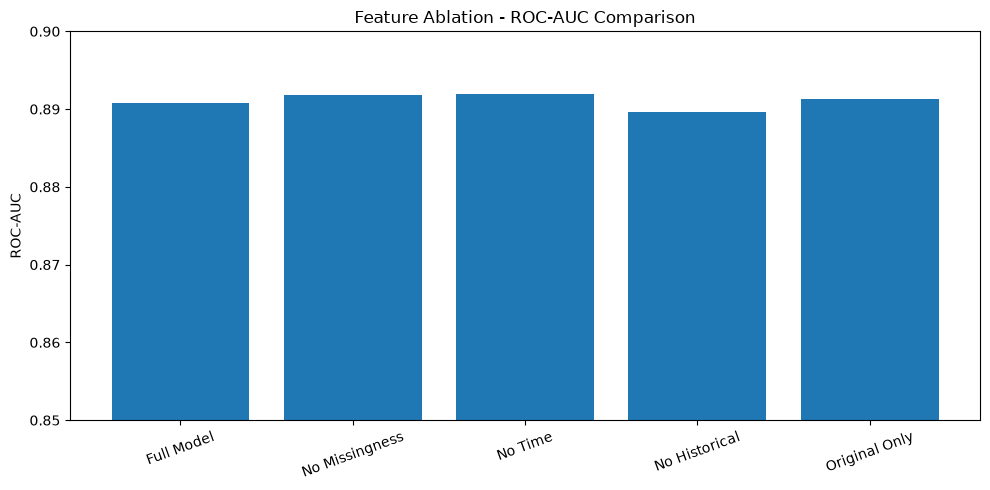

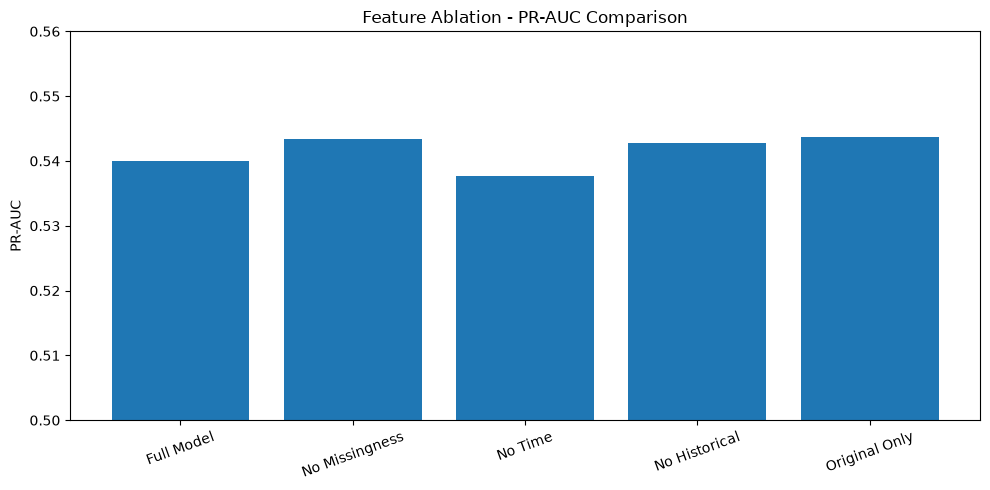

Both ablation graphs saved successfully.


In [4]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

RESULTS = Path(r"D:\Fraud-Detection\results")

df = pd.read_csv(
    RESULTS / "ablation_complete_comparison.csv"
)

# Friendly experiment labels
labels = {
    "full_model_retrained": "Full Model",
    "no_missingness": "No Missingness",
    "no_time": "No Time",
    "no_historical": "No Historical",
    "original_only": "Original Only"
}

df["label"] = df["experiment"].map(labels)

# ROC-AUC comparison
plt.figure(figsize=(10, 5))
plt.bar(df["label"], df["roc_auc"])
plt.title("Feature Ablation - ROC-AUC Comparison")
plt.ylabel("ROC-AUC")
plt.xticks(rotation=20)
plt.ylim(0.85, 0.90)
plt.tight_layout()

plt.savefig(
    RESULTS / "ablation_roc_auc_comparison.png",
    dpi=300
)
plt.show()

# PR-AUC comparison
plt.figure(figsize=(10, 5))
plt.bar(df["label"], df["pr_auc"])
plt.title("Feature Ablation - PR-AUC Comparison")
plt.ylabel("PR-AUC")
plt.xticks(rotation=20)
plt.ylim(0.50, 0.56)
plt.tight_layout()

plt.savefig(
    RESULTS / "ablation_pr_auc_comparison.png",
    dpi=300
)
plt.show()

print("Both ablation graphs saved successfully.")

In [5]:
import pandas as pd
from pathlib import Path

RESULTS = Path(r"D:\Fraud-Detection\results")

files = [
    "thursday_calibration_evaluation.csv",
    "thursday_threshold_comparison.csv",
    "thursday_best_thresholds.csv",
    "thursday_selected_thresholds.csv",
    "ablation_complete_comparison.csv",
    "shap_feature_comparison.csv"
]

for filename in files:
    path = RESULTS / filename

    print("\n" + "=" * 65)
    print(filename)
    print("=" * 65)

    if path.exists():
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head())
    else:
        print("FILE NOT FOUND")


thursday_calibration_evaluation.csv
Shape: (4, 5)
Columns: ['Model', 'Mean Predicted Probability', 'Actual Fraud Rate', 'Brier Score', 'Log Loss']


,Model,Mean Predicted Probability,Actual Fraud Rate,Brier Score,Log Loss
0,BCE Uncalibrated,0.031427,0.032715,0.023297,0.096962
1,BCE Platt,0.031904,0.032715,0.023329,0.097297
2,Focal Alpha 0.75 Uncalibrated,0.213101,0.032715,0.058730,0.259157
3,Focal Alpha 0.75 Platt,0.031794,0.032715,0.023619,0.097923



thursday_threshold_comparison.csv
Shape: (182, 9)
Columns: ['Model', 'Threshold', 'Precision', 'Recall', 'F1 Score', 'False Positives', 'False Negatives', 'True Positives', 'True Negatives']


,Model,Threshold,Precision,Recall,F1 Score,False Positives,False Negatives,True Positives,True Negatives
0,BCE,0.05,0.195785,0.685990,0.304628,4083,455,994,38759
1,BCE,0.06,0.222093,0.657695,0.332056,3338,496,953,39504
2,BCE,0.07,0.243494,0.632850,0.351678,2849,532,917,39993
3,BCE,0.08,0.270164,0.614907,0.375395,2407,558,891,40435
4,BCE,0.09,0.289771,0.584541,0.387466,2076,602,847,40766



thursday_best_thresholds.csv
Shape: (2, 9)
Columns: ['Model', 'Threshold', 'Precision', 'Recall', 'F1 Score', 'False Positives', 'False Negatives', 'True Positives', 'True Negatives']


,Model,Threshold,Precision,Recall,F1 Score,False Positives,False Negatives,True Positives,True Negatives
0,BCE,0.16,0.417920,0.460317,0.438095,929,782,667,41913
1,Focal Alpha 0.75,0.33,0.597274,0.332643,0.427305,325,967,482,42517


... (2 outputs left out)


ablation_complete_comparison.csv
Shape: (5, 8)
Columns: ['experiment', 'features', 'trees', 'roc_auc', 'pr_auc', 'training_time_seconds', 'roc_auc_change', 'pr_auc_change']


,experiment,features,trees,roc_auc,pr_auc,training_time_seconds,roc_auc_change,pr_auc_change
0,full_model_retrained,441,396,0.890833,0.539990,45.07,0.000000,0.000000
1,no_missingness,439,500,0.891873,0.543329,52.12,0.001040,0.003339
2,no_time,437,407,0.891961,0.537607,45.70,0.001129,-0.002382
3,no_historical,438,487,0.889575,0.542758,49.64,-0.001258,0.002768
4,original_only,432,480,0.891362,0.543733,48.59,0.000529,0.003743



shap_feature_comparison.csv
Shape: (441, 3)
Columns: ['Feature', 'BCE_SHAP_Importance', 'Focal_SHAP_Importance']


,Feature,BCE_SHAP_Importance,Focal_SHAP_Importance
0,TransactionAmt,0.193621,0.081264
1,P_emaildomain,0.161711,0.061445
2,C1,0.148908,0.053484
3,C13,0.136304,0.053728
4,C5,0.135040,0.088274


In [6]:
from pathlib import Path

RESULTS = Path(r"D:\Fraud-Detection\results")

print("AVAILABLE MODEL COMPARISON FILES")
print("=" * 60)

for path in sorted(RESULTS.glob("*.csv")):
    if any(word in path.name.lower() for word in [
        "model", "comparison", "performance", "metric"
    ]):
        print(path.name)

AVAILABLE MODEL COMPARISON FILES
ablation_complete_comparison.csv
ablation_full_model_metrics.csv
ablation_no_historical_metrics.csv
ablation_no_missingness_metrics.csv
ablation_no_time_metrics.csv
ablation_original_only_metrics.csv
calibration_comparison.csv
final_test_comparison.csv
focal_loss_model_comparison.csv
focal_threshold_comparison.csv
group_vs_complement_comparison.csv
model_comparison.csv
shap_feature_comparison.csv
temporal_performance.csv
thursday_false_negative_feature_comparison.csv
thursday_threshold_comparison.csv


In [7]:
import pandas as pd
from pathlib import Path

RESULTS = Path(r"D:\Fraud-Detection\results")

files = [
    "model_comparison.csv",
    "focal_loss_model_comparison.csv",
    "calibration_comparison.csv",
    "final_test_comparison.csv"
]

for filename in files:
    path = RESULTS / filename

    print("\n" + "=" * 75)
    print(filename)
    print("=" * 75)

    df = pd.read_csv(path)

    print("Shape:", df.shape)
    display(df)


model_comparison.csv
Shape: (3, 5)


,Model,ROC-AUC,Average Precision,Brier Score,Log Loss
0,Original LightGBM,0.903255,0.492417,0.022334,0.091513
1,Platt Scaling,0.903255,0.492417,0.022190,0.090295
2,Isotonic Regression,0.902598,0.473764,0.022230,0.091737



focal_loss_model_comparison.csv
Shape: (3, 4)


,Model,ROC-AUC,PR-AUC,Best Iteration
0,BCE,0.890833,0.539990,396
1,Focal Alpha 0.25,0.889444,0.532662,498
2,Focal Alpha 0.75,0.894671,0.534152,458



calibration_comparison.csv
Shape: (9, 4)


,Model,Method,Brier Score,Log Loss
0,BCE,Uncalibrated,0.023297,0.096962
1,BCE,Platt Scaling,0.023329,0.097297
2,BCE,Isotonic Regression,0.023396,0.098381
3,Focal Alpha 0.25,Uncalibrated,0.032862,0.167266
4,Focal Alpha 0.25,Platt Scaling,0.023659,0.098838
5,Focal Alpha 0.25,Isotonic Regression,0.023748,0.103241
6,Focal Alpha 0.75,Uncalibrated,0.058730,0.259157
7,Focal Alpha 0.75,Platt Scaling,0.023619,0.097923
8,Focal Alpha 0.75,Isotonic Regression,0.023747,0.098428



final_test_comparison.csv
Shape: (2, 9)


,Model,Threshold,ROC-AUC,PR-AUC,Precision,Recall,F1 Score,Brier Score,Log Loss
0,BCE,0.16,0.888311,0.503301,0.422193,0.512163,0.462846,0.022974,0.095464
1,Focal Alpha 0.75,0.33,0.889039,0.493521,0.623618,0.402530,0.489257,0.023240,0.096388



# Final Research Findings and Conclusions

## 1. Model Performance

The project evaluated Binary Cross-Entropy (BCE) and Focal Loss models for fraud detection using the IEEE-CIS dataset.

The model comparison on the validation sample showed:

| Model | ROC-AUC | PR-AUC |
|---|---:|---:|
| BCE | 0.890833 | 0.539990 |
| Focal Loss (α = 0.25) | 0.889444 | 0.532662 |
| Focal Loss (α = 0.75) | 0.894671 | 0.534152 |

Focal Loss with α = 0.75 achieved the highest ROC-AUC, while BCE achieved the highest PR-AUC.

This indicates that the two loss functions have different strengths. BCE performed better in average precision, while Focal Loss α = 0.75 achieved slightly better ranking performance according to ROC-AUC.

## 2. Probability Calibration

Calibration was evaluated using Brier Score, Log Loss, and reliability diagrams.

The BCE model already produced reasonably calibrated probabilities. Applying Platt Scaling or Isotonic Regression did not improve its calibration metrics in this evaluation.

The Focal Loss models, particularly α = 0.75, produced higher predicted probabilities than the actual fraud rate before calibration.

Platt Scaling substantially improved their probability estimates.

For Focal Loss α = 0.75:

- Uncalibrated Brier Score: 0.058730
- Platt-calibrated Brier Score: 0.023619
- Uncalibrated Log Loss: 0.259157
- Platt-calibrated Log Loss: 0.097923

This shows that calibration was especially useful for the Focal Loss model.

## 3. Threshold Selection

Thresholds were selected using the validation evaluation data.

| Model | Threshold | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|
| BCE | 0.16 | 0.417920 | 0.460317 | 0.438095 |
| Focal Loss α = 0.75 | 0.33 | 0.597274 | 0.332643 | 0.427305 |

The BCE model achieved higher recall, identifying more fraudulent transactions.

The Focal Loss model achieved higher precision and produced fewer false positives.

This demonstrates the trade-off between detecting more fraud and reducing false fraud alerts.

## 4. Final Chronological Test Evaluation

The final models were evaluated on the chronological test set using thresholds selected from validation data.

| Metric | BCE | Focal Loss α = 0.75 |
|---|---:|---:|
| Threshold | 0.16 | 0.33 |
| ROC-AUC | 0.888311 | 0.889039 |
| PR-AUC | 0.503301 | 0.493521 |
| Precision | 0.422193 | 0.623618 |
| Recall | 0.512163 | 0.402530 |
| F1-score | 0.462846 | 0.489257 |
| Brier Score | 0.022974 | 0.023240 |
| Log Loss | 0.095464 | 0.096388 |

The Focal Loss model achieved a slightly higher ROC-AUC and F1-score, along with considerably higher precision.

The BCE model achieved better PR-AUC, recall, Brier Score, and Log Loss.

Neither model is best across every metric. The choice depends on whether the priority is catching more fraudulent transactions or reducing false positives.

## 5. Feature Ablation Study

Ablation experiments were performed using the same fixed training and validation samples.

| Experiment | Features | ROC-AUC | PR-AUC |
|---|---:|---:|---:|
| Full Model | 441 | 0.890833 | 0.539990 |
| Without Missingness | 439 | 0.891873 | 0.543329 |
| Without Time | 437 | 0.891961 | 0.537607 |
| Without Historical | 438 | 0.889575 | 0.542758 |
| Original Features Only | 432 | 0.891362 | 0.543733 |

The results did not show a consistent improvement from adding all engineered feature groups.

Removing historical features reduced ROC-AUC, while removing time features produced a small improvement in ROC-AUC but reduced PR-AUC.

The original-features-only experiment achieved the highest PR-AUC in this ablation comparison.

These results should be interpreted carefully because the experiments used one random seed and a fixed validation sample. They do not establish that the engineered features are generally unnecessary.

## 6. SHAP Explainability

SHAP was used to understand which features contributed most to the model predictions.

For the BCE model, some of the highest-ranked features were:

- TransactionAmt
- P_emaildomain
- C1
- C13
- C5

For Focal Loss α = 0.75, the leading features included:

- C5
- TransactionAmt
- P_emaildomain
- C13
- C1

The SHAP results provide insight into model behaviour and feature contributions. They do not establish causal relationships between features and fraud.

## 7. Overall Conclusion

This project explored fraud detection under class imbalance and changing transaction patterns using the IEEE-CIS Fraud Detection dataset.

The work included data exploration, chronological data splitting, LightGBM modelling, Focal Loss experiments, feature engineering, adversarial validation, concept drift analysis, probability calibration, threshold selection, feature ablation, and SHAP explainability.

The experiments showed that:

1. BCE and Focal Loss have different performance characteristics.
2. Focal Loss α = 0.75 achieved higher precision and F1-score on the final test evaluation.
3. BCE achieved higher recall and better probability-quality metrics on the final test evaluation.
4. Platt Scaling substantially improved the probability estimates of the Focal Loss model.
5. Feature ablation did not demonstrate a consistent advantage from all engineered feature groups.
6. SHAP helped identify the features that contributed most to model predictions.

Overall, the project demonstrates that fraud detection is not only about selecting a model with a high ROC-AUC. Probability quality, threshold selection, false positives, missed fraud cases, feature behaviour, and changes in transaction patterns are also important.

## 8. Experimental Limitations

- The ablation study used one random seed and a fixed subset of the available data.
- Some ablation models reached the maximum training iteration limit.
- Calibration and threshold selection were performed using validation data.
- Final test results represent evaluation on the chronological test split and should not be used to tune the models.
- SHAP importance indicates model attribution, not causation.
- Results from different validation experiments and sample sizes should not be compared as though they came from one identical evaluation.

